# Predicting San Francisco Airbnb Prices

## Purpose

This notebook is a revisited and fixed version of a project I did with my team for INDENG 142A (Fall 2025). I went back to it, checked every step, fixed the problems I found, and tested the result honestly.

The question it answers: given what a San Francisco Airbnb is (its size, type, area and stay rules), what is the usual asking price for similar listings, and is this listing's price inside that range?

I build and test a price check. On hosts the model has never seen, a typical prediction is 19% off, and the real price falls within 0.67× to 1.5× of the prediction for 83% of listings. A listing priced more than twice its prediction is unusual (3% of listings), so it is worth a second look. The same work also gives a checklist for anyone using Inside Airbnb data: stale rows, placeholder prices, near-copy listings and a train/test split that flatters the score.

## What the data covers

- **Source:** Inside Airbnb, San Francisco, four snapshots (a snapshot is a copy of every listing on one day): Dec 2024, Mar 2025, Jun 2025 and Sep 2025.
- **Price:** the price the host asks for one night. It is not what guests actually paid.
- **Who the model is for:** homes and rooms in homes. Hotels, hostels and shared rooms are left out (section 4).

## About this notebook

The team's class project notebook is kept unchanged in `repo/`. This notebook is my rebuild and re-check of it. The original models, figures and report were produced by the team; the checks, fixes and this rebuild are mine.

## Sections

0. Data and audit *(done)*
1. Spatial features: distance to BART, Muni, attractions *(done)*
2. Season *(done)*
3. Cleaning *(done)*
4. Room and property type *(done)*
5. Feature engineering: host, amenities, neighbourhoods, bathrooms *(done)*
6. Price and outliers *(done)*
7. Missing values *(done)*
8. Evaluation design and models *(done)*
9. Results and drivers *(done)*

## 0. Data and audit

**Source.** [Inside Airbnb](https://insideairbnb.com/get-the-data/), San Francisco, detailed `listings` files for four **snapshots**. A snapshot is a copy of every listing on Airbnb's site on one day.

| Snapshot | Scrape date |
|---|---|
| Dec 2024 | 2024-12-04 |
| Mar 2025 | 2025-03-01 |
| Jun 2025 | 2025-06-17 |
| Sep 2025 | 2025-09-01 |

**How to read the data.** One row = one listing on one snapshot day. The same listing appears in several snapshots, which is what lets me see how its price changes through the year. It also means rows are **not independent**, which matters when I split the data for modelling (section 8).

**Limitations to keep in mind**
- `price` is the *asking* nightly price on the scrape date, not what guests actually paid.
- Four snapshots across one year cannot separate a seasonal pattern from a general trend.
- Winter is represented by one snapshot (Dec 2024).
- Later Inside Airbnb releases (Dec 2025 onward) are not used: Dec 2025 has no prices, and from 2026 the `price` field is a quoted-stay price and is not comparable with 2024-25.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 88
DATA_DIR = Path("data")

# label -> file, in chronological order
SNAPSHOTS = {
    "Dec 2024": "listings_dec24.csv",
    "Mar 2025": "listings_mar25.csv",
    "Jun 2025": "listings_jun25.csv",
    "Sep 2025": "listings_sep25.csv",
}

In [2]:
frames = []
for label, fname in SNAPSHOTS.items():
    snap = pd.read_csv(DATA_DIR / fname, low_memory=False)
    snap["snapshot"] = label
    frames.append(snap)

listings = pd.concat(frames, ignore_index=True)
listings["snapshot"] = pd.Categorical(listings["snapshot"], categories=list(SNAPSHOTS), ordered=True)

# price arrives as text like "$1,250.00"
listings["price"] = pd.to_numeric(
    listings["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"
)

# integrity checks
assert pd.api.types.is_integer_dtype(listings["id"]), "listing ids should load as integers"
assert not listings.duplicated(["id", "snapshot"]).any(), "a listing should appear once per snapshot"

listings.shape

(31278, 80)

### 0.1 Rows and listings per snapshot

In [3]:
per_snapshot = listings.groupby("snapshot", observed=True).agg(
    rows=("id", "size"),
    unique_listings=("id", "nunique"),
    scrape_dates=("last_scraped", lambda s: ", ".join(sorted(s.unique()))),
    price_missing=("price", lambda s: s.isna().mean()),
)
per_snapshot["price_missing"] = per_snapshot["price_missing"].map("{:.1%}".format)
per_snapshot

,rows,unique_listings,scrape_dates,price_missing
snapshot,,,,
Dec 2024,7863,7863,2024-12-04,20.8%
Mar 2025,7831,7831,"2025-03-01, 2025-03-02",23.2%
Jun 2025,7804,7804,2025-06-17,26.1%
Sep 2025,7780,7780,2025-09-01,25.5%


In [4]:
print(f"rows: {len(listings):,}   unique listings: {listings['id'].nunique():,}")

rows: 31,278   unique listings: 9,480


**31,278 rows are only 9,480 distinct listings.** Each snapshot has about 7,800 listings, one row each. These counts include rows carried over from an earlier scrape, which section 3 removes.

### 0.2 How many snapshots does each listing appear in?

In [5]:
n_snapshots = listings.groupby("id")["snapshot"].nunique()
appearances = n_snapshots.value_counts().sort_index().rename("listings").to_frame()
appearances["share"] = (appearances["listings"] / appearances["listings"].sum()).map("{:.1%}".format)
appearances.index.name = "snapshots_present"
appearances

,listings,share
snapshots_present,,
1,1134,12.0%
2,1184,12.5%
3,872,9.2%
4,6290,66.4%


In [6]:
# churn between consecutive snapshots
ids_by_snapshot = {label: set(g["id"]) for label, g in listings.groupby("snapshot", observed=True)}
labels = list(SNAPSHOTS)
churn = pd.DataFrame(
    [
        {
            "from -> to": f"{a} -> {b}",
            "kept": len(ids_by_snapshot[a] & ids_by_snapshot[b]),
            "dropped": len(ids_by_snapshot[a] - ids_by_snapshot[b]),
            "new": len(ids_by_snapshot[b] - ids_by_snapshot[a]),
        }
        for a, b in zip(labels[:-1], labels[1:])
    ]
).set_index("from -> to")
churn

,kept,dropped,new
from -> to,,,
Dec 2024 -> Mar 2025,7241,622,590
Mar 2025 -> Jun 2025,7104,727,700
Jun 2025 -> Sep 2025,7294,510,486


**About two thirds of listings (6,290 of 9,480) are in all four snapshots.** The rest come and go; roughly 7-9% of listings turn over between snapshots. These counts are for the data as loaded, before section 3 removes the carried-over rows. A listing that appears several times is the same place seen at different dates, so its rows carry almost the same information. I will split train and test **by host**, not by row (section 8).

### 0.3 Why is price missing?

In [7]:
missing = listings["price"].isna()
reasons = pd.DataFrame(
    {
        "rows": [missing.sum(), (~missing).sum()],
        "share_with_zero_availability": [
            (listings.loc[missing, "availability_365"] == 0).mean(),
            (listings.loc[~missing, "availability_365"] == 0).mean(),
        ],
        "median_reviews": [
            listings.loc[missing, "number_of_reviews"].median(),
            listings.loc[~missing, "number_of_reviews"].median(),
        ],
    },
    index=["price missing", "price present"],
)
reasons["share_with_zero_availability"] = reasons["share_with_zero_availability"].map("{:.1%}".format)
reasons

,rows,share_with_zero_availability,median_reviews
price missing,7478,61.6%,2.0
price present,23800,0.6%,10.0


In [8]:
still_open = (missing & (listings["availability_365"] > 0)).sum()
print(f"missing price but bookable (availability_365 > 0): {still_open:,} of {missing.sum():,} ({still_open / missing.sum():.0%})")

missing price but bookable (availability_365 > 0): 2,873 of 7,478 (38%)


**24% of rows have no price.** About 62% of them have zero availability for the next year (blocked calendars, likely inactive listings). The other 38% are open for booking and still have no price; section 3.1 explains why: they are rows carried over from an earlier scrape, whose availability is not current. Because the target is price, rows without one cannot be used for modelling; section 3 removes the carried-over rows and section 4 the few that remain.

### 0.4 Columns that differ between snapshots

In [9]:
cols_by_snapshot = {label: set(g.columns[g.notna().any()]) for label, g in listings.groupby("snapshot", observed=True)}
only_later = sorted(cols_by_snapshot["Mar 2025"] - cols_by_snapshot["Dec 2024"])
print("columns absent from the Dec 2024 file:", only_later)
print("share of rows from Dec 2024:", f"{(listings['snapshot'] == 'Dec 2024').mean():.1%}")

columns absent from the Dec 2024 file: ['availability_eoy', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'number_of_reviews_ly']
share of rows from Dec 2024: 25.1%


**Four columns do not exist in the Dec 2024 file** (`availability_eoy`, `estimated_occupancy_l365d`, `estimated_revenue_l365d`, `number_of_reviews_ly`), so they are empty for about a quarter of rows. This is a schema difference between releases, not random missingness. Dropping them (section 7) is correct, and it also keeps `estimated_revenue_l365d` (price x occupancy) out of the model, which would otherwise leak the target.

### 0.5 Extreme prices

In [10]:
priced = listings.dropna(subset=["price"])
print(priced["price"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_string())
print()
print("rows above $5,000:", (priced["price"] > 5000).sum())
priced.loc[priced["price"] > 5000, ["room_type", "price", "minimum_nights", "availability_365"]].head(8)

count    23800.0
mean       350.0
std       2264.0
min          9.0
50%        159.0
90%        449.0
99%       1523.0
max      50000.0

rows above $5,000: 85


,room_type,price,minimum_nights,availability_365
245,Entire home/apt,50000.0,30,182
848,Private room,6000.0,30,88
1356,Shared room,10000.0,45,180
1665,Private room,10000.0,1,365
2424,Entire home/apt,50000.0,30,132
2883,Entire home/apt,25000.0,30,365
3829,Entire home/apt,5300.0,1,81
6354,Entire home/apt,5555.0,2,10


**The maximum price is \$50,000 per night**, and 85 rows are above \$5,000. Many have round values (10,000; 25,000; 50,000) and 30-night minimums, which look like placeholders. I need an explicit rule for them (section 6).

### Takeaways from section 0
- 31,278 rows are 9,480 listings, each seen up to 4 times. **Rows are not independent**, so I will split the data into training and test sets by host, not by row (section 8). A listing's rows are almost copies of each other, and many hosts also have several near-identical listings.
- 24% of rows have no price. Most of them are listings carried over from an earlier scrape (section 3). I drop them, because the model needs a price to learn from.
- Four columns are empty for the whole Dec 2024 file, because that file has a different format. I drop them (section 7).
- Extreme prices (up to \$50,000 a night) need a rule (section 6).

## 1. Spatial features

Location is the main suspected price driver, so I give the model three distances per row, each in km: to the nearest **BART station**, the nearest **Muni stop**, and the nearest **tourist attraction** from a hand-made list.

### 1.1 The three place lists

In [11]:
import zipfile

import matplotlib.pyplot as plt
from lxml import etree
from pyproj import Geod, Transformer
from scipy.spatial import cKDTree


def load_bart(path):
    """Station name and coordinates from the BART KMZ (a zipped KML file)."""
    with zipfile.ZipFile(path) as kmz:
        root = etree.fromstring(kmz.read("doc.kml"))
    ns = {"k": "http://www.opengis.net/kml/2.2"}
    rows = []
    for placemark in root.iterfind(".//k:Placemark", ns):
        lon, lat, *_ = placemark.find(".//k:coordinates", ns).text.strip().split(",")
        rows.append({"name": placemark.find("k:name", ns).text, "lat": float(lat), "lon": float(lon)})
    return pd.DataFrame(rows)


bart = load_bart(DATA_DIR / "BART_Stations_2025.kmz")
muni = (
    pd.read_csv(DATA_DIR / "Muni_Stops_20251114.csv", usecols=["STOPNAME", "LATITUDE", "LONGITUDE"])
    .rename(columns={"STOPNAME": "name", "LATITUDE": "lat", "LONGITUDE": "lon"})
)
# this file is Mac Roman encoded ("Musée Mécanique"); reading it as UTF-8 fails
attractions = pd.read_csv(DATA_DIR / "sf_attractions.csv", encoding="mac_roman").rename(
    columns={"attraction": "name", "latitude": "lat", "longitude": "lon"}
)
attractions["name"] = attractions["name"].str.strip()

PLACES = {"bart": bart, "muni": muni, "attraction": attractions}
for key, df in PLACES.items():
    assert df[["lat", "lon"]].notna().all().all(), f"{key}: missing coordinates"
    assert df["lat"].between(36, 39).all() and df["lon"].between(-123, -119).all(), f"{key}: coordinates out of range"

pd.DataFrame(
    {
        key: {
            "rows": len(df),
            "distinct names": df["name"].nunique(),
            "lat range": f"{df['lat'].min():.3f} to {df['lat'].max():.3f}",
            "lon range": f"{df['lon'].min():.3f} to {df['lon'].max():.3f}",
        }
        for key, df in PLACES.items()
    }
).T

,rows,distinct names,lat range,lon range
bart,53,52,37.368 to 38.019,-122.469 to -121.780
muni,3264,3258,37.706 to 37.830,-122.511 to -122.367
attraction,60,60,36.600 to 38.297,-122.581 to -119.538


In [12]:
print("BART rows sharing a name:", bart["name"].duplicated(keep=False).sum(), "->", bart.loc[bart["name"].duplicated(keep=False), "name"].unique().tolist())
print("BART stations in the San Francisco area:", bart.loc[bart["lon"].lt(-122.38) & bart["lat"].between(37.70, 37.82), "name"].tolist())
print("Muni stops sharing exact coordinates:", muni.duplicated(["lat", "lon"]).sum())

BART rows sharing a name: 2 -> ['eBART Transfer']
BART stations in the San Francisco area: ['Civic Center/UN Plaza', 'Daly City', 'Glen Park', 'Balboa Park', '16th St/Mission', '24th St/Mission', 'Montgomery St', 'Powell St', 'Embarcadero']
Muni stops sharing exact coordinates: 2


- **BART**: 53 rows, the whole system from Milpitas to Antioch; only about nine stations are in or beside San Francisco. I keep them all, because a station just over the city line (Daly City) can be the nearest one for a listing near the border. One station (`eBART Transfer`, in Antioch) appears twice at the same point; it cannot affect any distance.
- **Muni**: 3,264 stops (every stop, both directions, so names repeat), within the city's bounding box.
- **Attractions**: 60 places compiled by hand. The file is Mac Roman, not UTF-8; the class notebook loaded it with `encoding_errors="ignore"`, which silently dropped the accented letters of *Musée Mécanique*. Read with the right encoding, the name is intact.
- The BART and Muni files are 2025 releases (Muni exported Nov 2025) and are applied to all four snapshots. Stops that opened or closed during 2024-25 are a small source of error I cannot measure here.

### 1.2 Computing the distances

In [13]:
# UTM zone 10N (EPSG:32610) is a flat metric grid, accurate to about 0.05% around San Francisco
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32610", always_xy=True)


def to_xy(lat, lon):
    x, y = to_utm.transform(np.asarray(lon), np.asarray(lat))
    return np.column_stack([x, y])


def nearest_place(df, places):
    """Straight-line distance in km, and name, of the nearest place for every row of df."""
    dist_m, idx = cKDTree(to_xy(places["lat"], places["lon"])).query(to_xy(df["latitude"], df["longitude"]))
    return dist_m / 1000, places["name"].to_numpy()[idx]


nearest_name = pd.DataFrame(index=listings.index)
for key, places in PLACES.items():
    listings[f"distance_to_{key}_km"], nearest_name[key] = nearest_place(listings, places)

DISTANCE_COLS = [f"distance_to_{key}_km" for key in PLACES]
assert listings[DISTANCE_COLS].notna().all().all()
listings[DISTANCE_COLS].describe(percentiles=[0.5, 0.9, 0.99]).round(3).T

,count,mean,std,min,50%,90%,99%,max
distance_to_bart_km,31278.0,1.836,1.596,0.003,1.255,4.320,7.182,8.211
distance_to_muni_km,31278.0,0.100,0.067,0.001,0.084,0.191,0.312,0.715
distance_to_attraction_km,31278.0,1.017,1.101,0.007,0.614,2.608,4.982,6.009


In [14]:
# check against exact distances on the WGS84 ellipsoid for a random sample of rows
geod = Geod(ellps="WGS84")
sample = listings.sample(300, random_state=SEED)
checks = {}
for key, places in PLACES.items():
    exact_m = np.array(
        [
            geod.inv(np.full(len(places), r.longitude), np.full(len(places), r.latitude), places["lon"].to_numpy(), places["lat"].to_numpy())[2].min()
            for r in sample.itertuples()
        ]
    )
    err = np.abs(sample[f"distance_to_{key}_km"].to_numpy() * 1000 - exact_m)
    checks[key] = {"max error (m)": err.max(), "max relative error": (err / exact_m).max()}
    assert (err / exact_m).max() < 1e-3, f"{key}: UTM distance is off by more than 0.1%"
pd.DataFrame(checks).T.round(4)

,max error (m),max relative error
bart,3.0331,0.0004
muni,0.1435,0.0004
attraction,2.0143,0.0004


**Distances are accurate to within a few metres.** I measure straight-line distances on a flat map grid in metres (UTM zone 10N). Compared with exact distances on the curved Earth for 300 random rows, the largest error is 3 m (0.04%). The class notebook did the same calculation more slowly, and stored every distance in both km and miles. I keep km only.

### 1.3 How the distances look

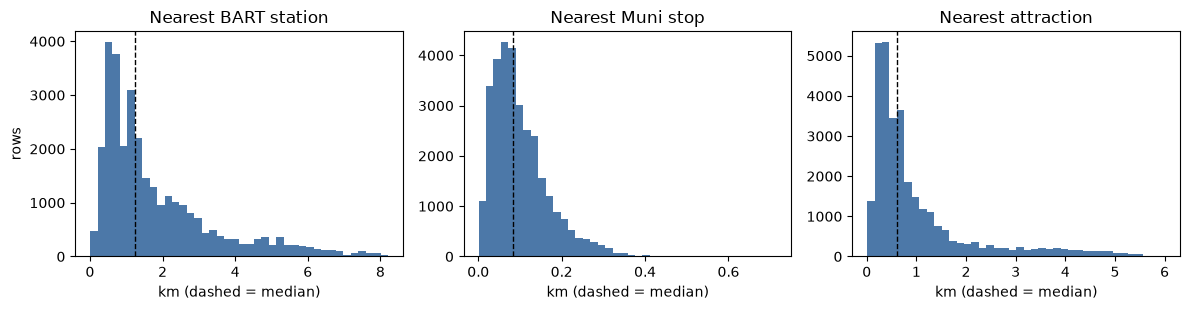

In [15]:
labels = {"bart": "BART station", "muni": "Muni stop", "attraction": "attraction"}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, key in zip(axes, PLACES):
    col = f"distance_to_{key}_km"
    ax.hist(listings[col], bins=40, color="#4c78a8")
    ax.axvline(listings[col].median(), color="black", lw=1, ls="--")
    ax.set_title(f"Nearest {labels[key]}")
    ax.set_xlabel("km (dashed = median)")
axes[0].set_ylabel("rows")
fig.tight_layout()
plt.show()

BART is the farthest away (median 1.3 km, up to 8.2 km). A Muni stop is almost always close (median 84 m, 99% of rows within about 310 m), so this feature has very little room to separate listings. Attractions sit in between (median 0.6 km, up to 6 km). All three are right-skewed.

### 1.4 The attractions list

In [16]:
# for each attraction: how often is it the nearest one, and how far is it from the closest listing?
closest_listing_km = cKDTree(to_xy(listings["latitude"], listings["longitude"])).query(to_xy(attractions["lat"], attractions["lon"]))[0] / 1000
attraction_use = pd.DataFrame(
    {
        "rows_where_nearest": attractions["name"].map(nearest_name["attraction"].value_counts()).fillna(0).astype(int).to_numpy(),
        "km_to_closest_listing": closest_listing_km.round(1),
    },
    index=attractions["name"],
)
print(f"attractions that are the nearest one for at least one row: {(attraction_use['rows_where_nearest'] > 0).sum()} of {len(attraction_use)}")
print()
print("most common nearest attraction:")
print((nearest_name["attraction"].value_counts(normalize=True).head(5) * 100).round(1).to_string())
print()
print("never the nearest attraction:")
attraction_use[attraction_use["rows_where_nearest"] == 0].sort_values("km_to_closest_listing", ascending=False)

attractions that are the nearest one for at least one row: 47 of 60

most common nearest attraction:
attraction
Mission District           15.1
Union Square                8.6
Twin Peaks                  7.2
Nob Hill                    7.0
16th Avenue Tiled Steps     5.5

never the nearest attraction:


,rows_where_nearest,km_to_closest_listing
name,,
Yosemite National Park,0,249.0
Monterey & Carmel tour,0,130.7
Napa & Sonoma wine tasting,0,54.4
Silicon Valley,0,46.2
Muir Woods National Monument,0,13.1
Angel Island,0,6.0
Sausalito,0,5.4
Point Bonita Lighthouse,0,4.2
Marin Headlands,0,2.6


**Decision: keep the list as given.** The five far-away entries (Yosemite, Monterey & Carmel, Napa & Sonoma, Silicon Valley, Muir Woods) are 13 to 249 km from the closest listing, so they are never the nearest attraction; removing them would change nothing. Pier 39 and the Academy of Sciences are only 0.3 and 0.4 km from the closest listing, yet they are never the nearest either: other entries in the list sit even closer to the same listings.

**What the feature really measures.** The list mixes tourist sites with neighbourhood centres (*Mission District* is the nearest entry for 15% of rows) and a few odd points (a restaurant, a roller rink). "Distance to the nearest attraction" is therefore better read as a coarse score for how central a listing is, not as a tourism measure. It is still useful as a feature; I just should not interpret it literally in section 9.

### 1.5 Do listing coordinates move between snapshots?

In [17]:
# a listing's position can differ by snapshot, so distances are computed per row, not per listing
xy = to_xy(listings["latitude"], listings["longitude"])
spread = pd.DataFrame({"id": listings["id"], "x": xy[:, 0], "y": xy[:, 1]}).groupby("id").agg(
    dx=("x", lambda s: s.max() - s.min()), dy=("y", lambda s: s.max() - s.min())
)
moved_m = np.hypot(spread["dx"], spread["dy"])
print(f"listings whose reported position changes at all: {(moved_m > 0).sum():,} of {len(moved_m):,}")
print(f"  by more than 100 m: {(moved_m > 100).sum():,}   by more than 500 m: {(moved_m > 500).sum():,}   largest: {moved_m.max():,.0f} m")

listings whose reported position changes at all: 2,051 of 9,480
  by more than 100 m: 1,462   by more than 500 m: 3   largest: 3,594 m


**Some listings move a little between snapshots**: 2,051 of 9,480 have a different position in at least one snapshot, 1,462 of them by more than 100 m (counted on all rows as loaded, including the carried-over ones). That is far below the scale of the BART and attraction distances (kilometres), but it is about the size of a typical Muni distance (84 m), so a Muni distance can shift by about as much as its typical value from one snapshot to the next. I compute every distance from the row's own coordinates. Three listings move more than 500 m (the largest 3.6 km); section 3.4 shows that each of them involves a carried-over row, and that no listing with fresh data moves more than 500 m.

### 1.6 First look at price

In [18]:
# descriptive only: rows are not independent and prices are not yet cleaned (section 6), so use ranks and medians
priced_rows = listings.dropna(subset=["price"])
print("Spearman correlation with price:")
print(priced_rows[DISTANCE_COLS].corrwith(priced_rows["price"], method="spearman").round(2).to_string())
print()
print("Spearman correlation between the three distances:")
print(listings[DISTANCE_COLS].corr(method="spearman").round(2).to_string())
print()
print("Median price (USD) by distance quartile, Q1 = closest:")
pd.DataFrame(
    {
        labels[key]: priced_rows.groupby(pd.qcut(priced_rows[f"distance_to_{key}_km"], 4, labels=["Q1", "Q2", "Q3", "Q4"]), observed=True)["price"].median()
        for key in PLACES
    }
)

Spearman correlation with price:


distance_to_bart_km         -0.03
distance_to_muni_km         -0.01
distance_to_attraction_km   -0.18

Spearman correlation between the three distances:
                           distance_to_bart_km  distance_to_muni_km  distance_to_attraction_km
distance_to_bart_km                       1.00                 0.14                       0.30
distance_to_muni_km                       0.14                 1.00                       0.27
distance_to_attraction_km                 0.30                 0.27                       1.00

Median price (USD) by distance quartile, Q1 = closest:


,BART station,Muni stop,attraction
Q1,170.0,159.0,199.0
Q2,149.0,165.0,155.0
Q3,175.5,160.0,160.0
Q4,144.0,150.0,134.0


**A first look, not a result.** Prices are not cleaned yet (section 6) and rows are not independent, so this only shows whether the distances look worth keeping.
- **Attraction distance** has the clearest link to price. The farther a listing is, the cheaper it tends to be (rank correlation -0.18). The median price is \$199 in the closest quarter of listings and \$134 in the farthest.
- **BART and Muni distance** show almost no link (BART -0.03, Muni about flat at \$150-165).
- The three distances are only weakly related to each other (0.30 at most), so none repeats another.

A weak link does not make a feature useless, because a tree model can pick up patterns that a correlation misses. I keep all three as inputs in section 8, and section 9.4 tests whether they help.

### Takeaways from section 1
- Three columns were added: `distance_to_bart_km`, `distance_to_muni_km` and `distance_to_attraction_km`.
- The attraction list mixes tourist sites and neighbourhood centres, so its distance means "how central is the listing", not "how close to the sights".
- Muni distance barely varies, and listing positions move by about as much as it varies, so it is a weak feature.
- I keep only the three distances in the data. The names of the nearest stops were only for checking.

## 2. Season

This section investigates how seasons influence the price, and how to give that information to the model.

The class notebook did not take season into account. It turned the scrape date into a text column (`year_month`), but its modelling step kept only number columns, so that column never reached any model. I also found no chart or code in it that measures the effect of season.

Here I measure the effect first, by comparing the prices of the same listings across the four snapshots. Then I give the model one 0/1 column per snapshot, so season is part of it on purpose.

### 2.1 What the snapshot dates are

In [19]:
from scipy.stats import trim_mean

scrape_date = pd.to_datetime(listings["last_scraped"])
snapshot_dates = scrape_date.groupby(listings["snapshot"], observed=True).agg(first="min", last="max")
snapshot_dates["rows"] = listings.groupby("snapshot", observed=True).size()
# each snapshot sits inside one calendar month, so "snapshot" and "year-month" are the same variable
assert (snapshot_dates["first"].dt.to_period("M") == snapshot_dates["last"].dt.to_period("M")).all()
snapshot_dates

,first,last,rows
snapshot,,,
Dec 2024,2024-12-04,2024-12-04,7863
Mar 2025,2025-03-01,2025-03-02,7831
Jun 2025,2025-06-17,2025-06-17,7804
Sep 2025,2025-09-01,2025-09-01,7780


Each snapshot was scraped within one calendar month (Mar 2025 took two days), so the class notebook's `year_month` is the same variable as `snapshot`, and there is nothing finer to add. Four dates are also too few to show any weekday effect.

### 2.2 Do prices differ between snapshots?

In [20]:
# the same listings priced in all four snapshots: a change here is a price change, not a change in who is listed
price_wide = listings.pivot(index="id", columns="snapshot", values="price")
matched = price_wide.dropna()
log_price = np.log(matched)
log_vs_dec = log_price.sub(log_price["Dec 2024"], axis=0)
log_step = log_price.diff(axis=1)

TRIM = 0.05  # average after cutting the top and bottom 5% of changes, so a few placeholder prices cannot dominate
rng = np.random.default_rng(SEED)
resample_idx = rng.integers(0, len(matched), size=(2000, len(matched)))  # resample listings, not rows


def trimmed_change(log_change):
    """Trimmed mean log change as a percentage change, with a 95% interval from resampling listings."""
    values = log_change.to_numpy()
    point = np.expm1(trim_mean(values, TRIM))
    low, high = np.expm1(np.percentile(trim_mean(values[resample_idx], TRIM, axis=1), [2.5, 97.5]))
    return point, low, high


rows = []
for label in SNAPSHOTS:
    vs_dec = log_vs_dec[label]
    point, low, high = trimmed_change(vs_dec)
    rows.append(
        {
            "snapshot": label,
            "median price (matched)": matched[label].median(),
            "change vs previous": np.nan if label == "Dec 2024" else np.expm1(trim_mean(log_step[label], TRIM)),
            "change vs Dec 2024": point,
            "interval low": low,
            "interval high": high,
            "raised vs Dec": (vs_dec > 0).mean(),
            "lowered vs Dec": (vs_dec < 0).mean(),
            "median price (all priced rows)": listings.loc[listings["snapshot"] == label, "price"].median(),
        }
    )
by_snapshot = pd.DataFrame(rows).set_index("snapshot")

dec_prices = listings.loc[listings["snapshot"] == "Dec 2024", "price"]
print(f"listings priced in all four snapshots: {len(matched):,} of {listings['id'].nunique():,}")
print(f"for scale: the middle half of Dec 2024 prices runs from ${dec_prices.quantile(0.25):.0f} to ${dec_prices.quantile(0.75):.0f}")
by_snapshot.style.format(
    {
        "median price (matched)": "{:.0f}",
        "median price (all priced rows)": "{:.0f}",
        **{c: "{:+.1%}" for c in ["change vs previous", "change vs Dec 2024", "interval low", "interval high"]},
        **{c: "{:.0%}" for c in ["raised vs Dec", "lowered vs Dec"]},
    },
    na_rep="",
)

listings priced in all four snapshots: 3,737 of 9,480
for scale: the middle half of Dec 2024 prices runs from $90 to $240


,median price (matched),change vs previous,change vs Dec 2024,interval low,interval high,raised vs Dec,lowered vs Dec,median price (all priced rows)
snapshot,,,,,,,,
Dec 2024,150,,+0.0%,+0.0%,+0.0%,0%,0%,148
Mar 2025,150,+2.1%,+2.1%,+1.5%,+2.6%,40%,34%,151
Jun 2025,163,+7.9%,+10.5%,+9.6%,+11.4%,56%,25%,169
Sep 2025,163,-0.1%,+10.4%,+9.6%,+11.2%,59%,26%,170


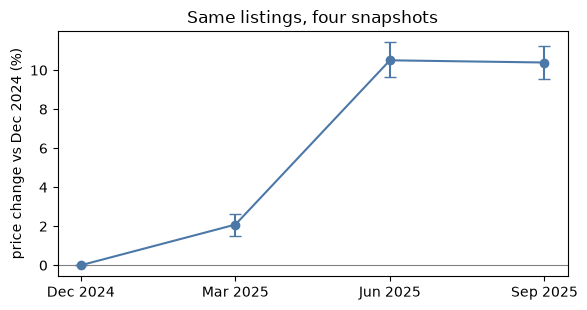

In [21]:
fig, ax = plt.subplots(figsize=(6, 3.2))
change = by_snapshot["change vs Dec 2024"] * 100
ax.errorbar(
    range(len(by_snapshot)),
    change,
    yerr=[change - by_snapshot["interval low"] * 100, by_snapshot["interval high"] * 100 - change],
    marker="o", color="#4c78a8", capsize=4,
)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(range(len(by_snapshot)), by_snapshot.index)
ax.set_ylabel("price change vs Dec 2024 (%)")
ax.set_title("Same listings, four snapshots")
fig.tight_layout()
plt.show()

**For the same listings, prices step up by about 10% between March and June and then stay there.** Against Dec 2024 the average change is +2.1% in Mar 2025, +10.5% in Jun 2025 and +10.4% in Sep 2025 (average after trimming the extreme 5% at each end; the interval comes from resampling listings). By September 59% of these listings charge more than in December and 26% charge less. The all-rows medians in the last column rise a little more (\$148 to \$170, +15%), because the set of listings also changes from snapshot to snapshot.

**This is a modest effect.** A 10% shift is small next to the differences between listings: the middle half of December prices runs from \$90 to \$240. Season will help the model, but it will not be a main driver.

**What I can and cannot say.**
- The pattern is consistent with higher summer and early-autumn prices, but one year of data cannot tell a seasonal swing from a general rise in asking prices over 2025. Winter is a single snapshot (Dec 2024), so no second winter is available to check against.
- The 3,737 listings priced in all four snapshots are survivors (39% of the 9,480 listings as loaded, 45% of the 8,279 left after section 3), and may differ from the rest. The interval measures sampling noise only, not that selection.
- `price` is an asking price on the scrape date (section 0), so this describes list prices, not what guests paid.

### 2.3 How the model will see it

In [22]:
# one 0/1 column per snapshot; section 8 drops one of them for the linear model
for label in SNAPSHOTS:
    listings["snap_" + label.lower().replace(" ", "_")] = (listings["snapshot"] == label).astype(int)

SEASON_COLS = [c for c in listings.columns if c.startswith("snap_")]
assert (listings[SEASON_COLS].sum(axis=1) == 1).all()
listings[SEASON_COLS].sum().to_frame("rows")

,rows
snap_dec_2024,7863
snap_mar_2025,7831
snap_jun_2025,7804
snap_sep_2025,7780


**The season enters as four 0/1 columns, one per snapshot** (`snap_dec_2024`, `snap_mar_2025`, `snap_jun_2025`, `snap_sep_2025`). They allow any pattern across the four dates, such as the step seen above, rather than forcing a straight-line trend or a made-up season label. Tree models can use all four; the linear model in section 8 will drop one to avoid redundancy.

Two consequences for later sections:
- The test set will hold unseen **hosts** (and their listings) drawn from the same four snapshots. The model will therefore not be tested on a new time of year, and a good score says nothing about forecasting a future season.
- With one year of data, the season coefficients must not be reported as a pure seasonal effect in section 9.

### Takeaways from section 2
- For the same 3,737 listings, prices are about 2% higher in Mar 2025 and about 10% higher in Jun and Sep 2025 than in Dec 2024. The effect is real but small next to differences between listings.
- Season cannot be separated from a general price trend with four snapshots in one year.
- New columns: `snap_dec_2024`, `snap_mar_2025`, `snap_jun_2025`, `snap_sep_2025`.

## 3. Cleaning

This section removes the rows and columns that should not go into a model, and checks the data for duplicates, impossible values and listings whose identity changes over time.

**What the class notebook did.** It dropped 12 columns by hand. It ran one duplicate check, but that check compared rows on `id` as well, so it could never find anything and always printed 0. It never checked for impossible values.

It also dropped rows with a missing price without saying so. It kept only rows with `price <= q75` (a price at or below the 75th percentile, \$270), and a missing price fails that test. When I replayed its filters on the four data files, I got exactly its numbers: 26,277 rows before the cut-off and 15,810 after. The 5,203 missing-price rows were among the rows lost. Its later comment "the price column contains no missing values" is true only because of this.

In [23]:
# replay of the class notebook's filters (its cells 34, 44 and 69) on the data as loaded, to see where its missing-price rows went
original_property_removals = [
    "Room in hotel", "Room in boutique hotel", "Private room in hostel", "Room in aparthotel",
    "Private room in bed and breakfast", "Entire resort", "Campsite",
]
replay = listings[~listings["room_type"].isin(["Hotel room", "Shared room"]) & ~listings["property_type"].isin(original_property_removals)]
cutoff = replay["price"].quantile(0.75)
kept = replay[replay["price"] <= cutoff]  # a missing price compares as False, so those rows are dropped here
print(f"rows after the class notebook's room and property type filters: {len(replay):,}  (the class notebook printed 26,277)")
print(f"75th percentile of price: {cutoff:.0f}  (the class notebook printed 270)")
print(f"rows kept by price <= that: {len(kept):,}  (the class notebook printed 15,810)")
print(f"rows without a price: {replay['price'].isna().sum():,} before the cut-off, {kept['price'].isna().sum()} after")

rows after the class notebook's room and property type filters: 26,277  (the class notebook printed 26,277)
75th percentile of price: 270  (the class notebook printed 270)
rows kept by price <= that: 15,810  (the class notebook printed 15,810)
rows without a price: 5,203 before the cut-off, 0 after


### 3.1 Rows that were not scraped this time

The `source` column has two values. Inside Airbnb's data dictionary describes `previous scrape` as a listing seen in another scrape within the last 65 days; the other value, `city scrape`, corresponds to the dictionary's "neighbourhood search" (found by searching the city).

In [24]:
by_source = listings.groupby(["snapshot", "source"], observed=True).agg(
    rows=("id", "size"),
    has_price=("price", lambda s: s.notna().mean()),
    blocked_calendar=("availability_365", lambda s: (s == 0).mean()),
    reviews_last_30d=("number_of_reviews_l30d", "mean"),
)
by_source.style.format({"has_price": "{:.0%}", "blocked_calendar": "{:.0%}", "reviews_last_30d": "{:.2f}"})

**Carried-over rows (`previous scrape`) never have a price.** Their calendars are mostly blocked (57-72%, against 0-1% for fresh rows) and they have far fewer recent reviews. That fits listings that this scrape's search did not find.

In [25]:
carried_over = listings["source"] == "previous scrape"
no_price = listings["price"].isna()
print(f"carried-over rows: {carried_over.sum():,} of {len(listings):,} ({carried_over.mean():.1%})")
print(f"rows without a price: {no_price.sum():,}, of which carried over: {(no_price & carried_over).sum():,}")
assert listings.loc[carried_over, "price"].isna().all()

carried-over rows: 7,315 of 31,278 (23.4%)
rows without a price: 7,478, of which carried over: 7,315


**These rows explain almost all the missing prices.** 7,315 of 31,278 rows (23.4%) are carried over, and they make up 7,315 of the 7,478 rows with no price (98%). This answers the open question from section 0.3: the "bookable but no price" rows are carried-over rows, and their availability comes from an earlier scrape, so it says little about whether they can be booked now. Only 163 fresh rows lack a price.

**Decision: drop the carried-over rows.** They have no price to learn from, and their other fields are not from the snapshot date. The counts in section 0 (about 7,800 listings per snapshot, the 6-9% turnover) include them; the fresh rows per snapshot are 6,242, 6,057, 5,813 and 5,851. The 163 fresh rows without a price stay for now; section 4 shows that they are all hotel-style rooms and drops them with those.

In [26]:
raw = {"rows": len(listings), "listings": listings["id"].nunique(), "columns": listings.shape[1]}

listings = listings.loc[~carried_over].copy()

print(f"rows: {raw['rows']:,} -> {len(listings):,}   listings: {raw['listings']:,} -> {listings['id'].nunique():,}")
print(f"rows still without a price: {listings['price'].isna().sum():,}")

rows: 31,278 -> 23,963   listings: 9,480 -> 8,279
rows still without a price: 163


### 3.2 Columns that can never be features

I drop columns by rule, not by hand: empty or single-valued columns, web links, and copies of another column. `id`, `host_id` and `snapshot` stay, because the train/test split in section 8 needs them.

In [27]:
objects = listings.select_dtypes("object")
url_cols = [c for c in objects if objects[c].dropna().astype(str).str.startswith("http").mean() > 0.9]
constant_cols = [c for c in listings.columns if listings[c].nunique(dropna=True) <= 1]  # empty, or one value

assert (listings["calendar_last_scraped"] == listings["last_scraped"]).all()
assert listings.groupby("snapshot", observed=True)["scrape_id"].nunique().eq(1).all()
assert listings["scrape_id"].nunique() == listings["snapshot"].nunique()
# `neighbourhood` is a heading copied from neighborhood_overview, not an area name (the area is neighbourhood_cleansed)
assert (listings["neighbourhood"].notna() == listings["neighborhood_overview"].notna()).all()

why_dropped = {c: "empty, or a single value" for c in constant_cols}
why_dropped.update({c: "web link" for c in url_cols})
why_dropped.update(
    {
        "calendar_last_scraped": "identical to last_scraped",
        "scrape_id": "one value per snapshot",
        "last_scraped": "date is already in snapshot",
    }
)
listings = listings.drop(columns=list(why_dropped))
assert {"id", "host_id", "snapshot", "price"} <= set(listings.columns)

print(f"columns: {raw['columns']} -> {listings.shape[1]}")
pd.Series(why_dropped, name="why dropped").to_frame()

columns: 87 -> 74


,why dropped
source,"empty, or a single value"
neighbourhood,"empty, or a single value"
neighbourhood_group_cleansed,"empty, or a single value"
calendar_updated,"empty, or a single value"
has_availability,"empty, or a single value"
listing_url,web link
picture_url,web link
host_url,web link
host_thumbnail_url,web link
host_picture_url,web link


**13 columns go.** The list matches the class notebook's hand-picked one (cell 30, plus `last_scraped` from cell 27 and `has_availability` from cell 90), with one difference: the class notebook also dropped `host_neighbourhood`, which I keep in the data; section 5.5 later decides not to use it as a feature. `neighbourhood` is a heading copied from `neighborhood_overview` (present exactly when that is), not an area name; the area is `neighbourhood_cleansed`. `has_availability` is always `t` once the carried-over rows are gone.

### 3.3 Duplicates

In [28]:
non_id_cols = [c for c in listings.columns if c != "id"]
twin_key = ["snapshot", "host_id", "latitude", "longitude", "name", "room_type", "accommodates", "bedrooms", "price"]
exact_copy = listings.duplicated(non_id_cols, keep=False)
twin = listings.duplicated(twin_key, keep=False)

pd.DataFrame(
    {
        "rows": [exact_copy.sum(), twin.sum()],
        "share of rows": [exact_copy.mean(), twin.mean()],
        "listings": [listings.loc[exact_copy, "id"].nunique(), listings.loc[twin, "id"].nunique()],
        "hosts": [listings.loc[exact_copy, "host_id"].nunique(), listings.loc[twin, "host_id"].nunique()],
    },
    index=["identical in every column except id", "same host, place, name, type, size and price"],
).style.format({"share of rows": "{:.1%}"})

,rows,share of rows,listings,hosts
identical in every column except id,301,1.3%,111,5
"same host, place, name, type, size and price",709,3.0%,238,10


The class notebook's check could not fire (see above). Checked properly, there are two kinds of near-copies:
- **301 rows** (1.3%, 111 listings, 5 hosts) are identical to another row in every column except `id`.
- **709 rows** (3.0%, 238 listings, 10 hosts) share host, coordinates, name, room type, size and price within a snapshot.

In [29]:
(
    listings.loc[twin]
    .groupby("host_id")
    .agg(rows=("id", "size"), listings=("id", "nunique"), example_name=("name", "first"))
    .sort_values("rows", ascending=False)
    .head(6)
)

,rows,listings,example_name
host_id,,,
442029804,268,81,"The Ritz-Carlton Club, San Francisco 1-Bedroom"
482174715,151,43,"The Ritz-Carlton Club®, San Francisco 3 Bedroom"
389697794,110,30,Chic King Suite at Wyndham Donatello in SF
480237365,105,33,"The Ritz-Carlton Club, San Francisco 1-Bedroom"
107434423,36,27,"Blueground | Rincon Hill, gym, rooftop, nr tech"
542041520,16,7,Lovely Boutique Hotel In Central Downtown


The 709 twin rows are mostly hotel-style inventory: four hosts account for 634 of them (three list timeshare and resort-club rooms under several brands (The Ritz-Carlton Club, Wyndham, Marriott Vacation Club)), plus Blueground apartments. Next, a closer look at the stricter group, the 301 rows that match in every column except `id`. The photo links were dropped in 3.2, so they are read again from the files.

In [30]:
copies = listings[exact_copy].copy()
copies["group"] = copies.groupby(non_id_cols, dropna=False, observed=True).ngroup()
photos = pd.concat(
    [pd.read_csv(DATA_DIR / fname, usecols=["id", "picture_url"]).assign(snapshot=label) for label, fname in SNAPSHOTS.items()]
)
copies = copies.merge(photos, on=["id", "snapshot"], how="left")

by_group = copies.groupby("group")
pd.Series(
    {
        "groups of identical rows": by_group.ngroups,
        "rows per group (smallest, largest)": f"{by_group.size().min()}, {by_group.size().max()}",
        "groups where every row has its own photo file": int((by_group["picture_url"].nunique() == by_group.size()).sum()),
        "groups where some row has reviews": int((by_group["number_of_reviews"].max() > 0).sum()),
        "share of rows from the three largest hosts": copies["host_id"].isin(copies["host_id"].value_counts().head(3).index).mean().round(3),
    },
    name="the 301 exact-copy rows",
).to_frame()

,the 301 exact-copy rows
groups of identical rows,101
"rows per group (smallest, largest)","2, 8"
groups where every row has its own photo file,99
groups where some row has reviews,0
share of rows from the three largest hosts,0.973


**What the 301 rows are.** They form 101 groups of 2 to 8 listings. Almost all (97%) come from three hosts that rent timeshare and resort-club rooms (The Ritz-Carlton Club, Wyndham, Marriott Vacation Club). Each listing has its own id and link, and nearly always its own photo file, so they are separate listings, not one row repeated. But everything else is the same: price, text, amenities and calendar (identical availability for the next 30, 60, 90 and 365 days), and not one of them has a review. Separate rooms would rarely have the same calendar to the day, so these look like copies of one room type listed several times. I cannot tell from the data whether each copy is a different physical room.

**Decision: I keep them for now.** They are only 1.3% of rows, and removing them is a judgement call. But they are not independent examples, so I will split the data by host (section 8), so that copies do not land on both the training and test side. If the model seems to overweight them, I can drop the 200 extra copies (0.8%). Section 4.4 looks at these hosts again.

### 3.4 Is a listing id the same place over time?

In [31]:
xy = to_xy(listings["latitude"], listings["longitude"])  # defined in section 1
per_id = (
    pd.DataFrame(
        {"id": listings["id"].to_numpy(), "x": xy[:, 0], "y": xy[:, 1], "host_id": listings["host_id"].to_numpy(), "room_type": listings["room_type"].to_numpy()}
    )
    .groupby("id")
    .agg(dx=("x", lambda s: s.max() - s.min()), dy=("y", lambda s: s.max() - s.min()), hosts=("host_id", "nunique"), room_types=("room_type", "nunique"))
)
moved_m = np.hypot(per_id["dx"], per_id["dy"])
print(f"listings: {len(per_id):,}")
print(f"position changes at all: {(moved_m > 0).sum():,}   by more than 100 m: {(moved_m > 100).sum():,}   by more than 500 m: {(moved_m > 500).sum():,}   largest: {moved_m.max():,.0f} m")
print(f"listings with more than one host over time: {(per_id['hosts'] > 1).sum()}   with more than one room type: {(per_id['room_types'] > 1).sum()}")

listings: 8,279
position changes at all: 1,572   by more than 100 m: 1,116   by more than 500 m: 0   largest: 332 m
listings with more than one host over time: 47   with more than one room type: 49


**A listing id is the same place over time.** Once the carried-over rows are removed, no listing moves more than 500 m (the largest move is 332 m). The three listings that looked like they moved up to 3.6 km in section 1 all involve a carried-over row.

Some details do change: 47 listings have more than one host over time (probably sold or handed to a manager), and 49 change room type (for example a private room that becomes an entire home). These are real changes, so I keep them, and each row's features describe that row's snapshot. This matters for section 8: a listing that changes host must still stay on one side of the train/test split.

In [32]:
# does a "new" listing look like an old one that came back under a new id?
place = listings.assign(spot=listings["latitude"].round(3).astype(str) + "_" + listings["longitude"].round(3).astype(str))
place_key = ["host_id", "spot", "room_type", "bedrooms"]  # same host, about the same 100 m cell, same kind, same bedrooms
labels = list(SNAPSHOTS)
rows = []
for i in range(1, len(labels)):
    seen_before = set(place.loc[place["snapshot"].isin(labels[:i]), "id"])
    now = place[place["snapshot"] == labels[i]]
    new = now[~now["id"].isin(seen_before)]
    vanished = place[place["snapshot"].isin(labels[:i]) & ~place["id"].isin(now["id"])].drop_duplicates("id", keep="last")
    match = new.merge(vanished[[*place_key, "name"]], on=place_key, suffixes=("", "_old"))
    rows.append(
        {
            "snapshot": labels[i],
            "new listings": len(new),
            "match a vanished one": match["id"].nunique(),
            "and have the same name": match.loc[match["name"] == match["name_old"], "id"].nunique(),
        }
    )
pd.DataFrame(rows).set_index("snapshot")

,new listings,match a vanished one,and have the same name
snapshot,,,
Mar 2025,894,60,1
Jun 2025,681,49,2
Sep 2025,462,43,6


**There is no sign of listings coming back under a new id.** Of 2,037 new listings, 152 match a vanished one on host, location (about 100 m), room type and bedrooms, and only 9 have the same name. The rest are most likely other units of the same host in the same building. Nothing is changed.

### 3.5 Impossible values

In [33]:
scrape_day = scrape_date.loc[listings.index]  # from section 2
checks = {
    "price of zero or less": listings["price"] <= 0,
    "minimum_nights below 1": listings["minimum_nights"] < 1,
    "minimum_nights above maximum_nights": listings["minimum_nights"] > listings["maximum_nights"],
    "accommodates below 1": listings["accommodates"] < 1,
    "negative bedrooms or beds": (listings["bedrooms"] < 0) | (listings["beds"] < 0),
    "availability_365 outside 0-365": ~listings["availability_365"].between(0, 365),
    "availability windows out of order (30 > 60 > 90 > 365)": (listings["availability_30"] > listings["availability_60"]) | (listings["availability_60"] > listings["availability_90"]) | (listings["availability_90"] > listings["availability_365"]),
    "reviews in last 12 months above all reviews": listings["number_of_reviews_ltm"] > listings["number_of_reviews"],
    "review score outside 0-5": (listings["review_scores_rating"] < 0) | (listings["review_scores_rating"] > 5),
    "review score but no reviews, or reviews but no score": (listings["number_of_reviews"] == 0) != listings["review_scores_rating"].isna(),
    "host joined after the scrape date": pd.to_datetime(listings["host_since"]) > scrape_day,
    "first review after last review": pd.to_datetime(listings["first_review"]) > pd.to_datetime(listings["last_review"]),
}
impossible = pd.Series({name: int(mask.sum()) for name, mask in checks.items()}, name="rows")
impossible.to_frame()

,rows
price of zero or less,0
minimum_nights below 1,0
minimum_nights above maximum_nights,0
accommodates below 1,0
negative bedrooms or beds,0
availability_365 outside 0-365,0
availability windows out of order (30 > 60 > 90 > 365),0
reviews in last 12 months above all reviews,0
review score outside 0-5,0
"review score but no reviews, or reviews but no score",0


**None of the 12 checks finds an impossible value**, so no row is removed for being invalid (the class notebook did not check). Four things are odd but possible. 13 listings require a stay of more than a year. 11 have `maximum_nights` above 3,650, up to 999,999, a placeholder, so that column is not usable as it is; section 5.5 caps it at 1,125. 2,236 listings have 0 bedrooms, which is normal for studios.

In [34]:
odd_but_possible = pd.Series(
    {
        "minimum_nights above 365": int((listings["minimum_nights"] > 365).sum()),
        "maximum_nights above 3,650 (largest: " + f"{listings['maximum_nights'].max():,})": int((listings["maximum_nights"] > 3650).sum()),
        "bedrooms = 0 (studios)": int((listings["bedrooms"] == 0).sum()),
        "beds = 0": int((listings["beds"] == 0).sum()),
    },
    name="rows",
)
odd_but_possible.to_frame()

,rows
minimum_nights above 365,13
"maximum_nights above 3,650 (largest: 999,999)",11
bedrooms = 0 (studios),2236
beds = 0,436


### 3.6 What is left

In [35]:
pd.DataFrame(
    {"before": raw, "after": {"rows": len(listings), "listings": listings["id"].nunique(), "columns": listings.shape[1]}}
).assign(removed=lambda t: t["before"] - t["after"])

,before,after,removed
rows,31278,23963,7315
listings,9480,8279,1201
columns,87,74,13


### Takeaways from section 3
- **7,315 carried-over rows (23.4%) are removed.** They have no price and their data is not from the snapshot date. They explain 98% of the missing prices, including the "bookable but no price" puzzle from section 0.3. What is left: 23,963 rows, 8,279 listings.
- **13 columns are dropped by rule** (empty or single-valued, web links, copies). `id`, `host_id` and `snapshot` are kept for the split in section 8.
- **No duplicates are removed.** 301 rows are exact copies except `id`: 101 groups of separate listings with identical content, calendars and no reviews, almost all from three hosts that list timeshare and resort-club rooms. They look like templated copies, not independent observations. Kept, with section 8 splitting by host so copies cannot land on both sides.
- **No impossible values; listing ids are stable places.** The three big movers from section 1 were carried-over rows.
- **The class notebook's cleaning did less than it seems:** its duplicate check could not fire, it checked no validity, and its 5,203 missing-price rows were lost silently in the price cut-off.

## 4. Room and property type

This section decides which kinds of listing the model is for, and how to describe the type of place to the model.

**What the class notebook did.** It kept only `Entire home/apt` and `Private room`, and dropped `Hotel room` and `Shared room` because their prices looked "extremely noisy and not representative". Then it turned the seven most common property types (plus "Other") into 0/1 columns, and only after that removed seven hand-picked property types (hotels, hostels, bed and breakfasts, resorts, campsites). That order caused a mistake: `Room in hotel` was one of the seven columns, and once the hotel rows were removed, its column was 0 for every row. It also never checked that room type and property type agree.

### 4.1 Room types

In [36]:
by_room = listings.groupby("room_type").agg(
    rows=("id", "size"),
    listings=("id", "nunique"),
    priced=("price", "count"),
    median_price=("price", "median"),
    median_if_under_5000=("price", lambda s: s[s <= 5000].median()),
    p90_price=("price", lambda s: s.quantile(0.9)),
    priced_over_5000=("price", lambda s: (s > 5000).sum()),
)
by_room["share_over_5000"] = by_room["priced_over_5000"] / by_room["priced"]
by_room.style.format({"median_price": "{:.0f}", "median_if_under_5000": "{:.0f}", "p90_price": "{:,.0f}", "share_over_5000": "{:.1%}"})

,rows,listings,priced,median_price,median_if_under_5000,p90_price,priced_over_5000,share_over_5000
room_type,,,,,,,,
Entire home/apt,15481,5169,15481,199,199,525,21,0.1%
Hotel room,312,191,312,234,210,"40,000",50,16.0%
Private room,8054,2908,7891,87,87,237,10,0.1%
Shared room,116,60,116,51,50,178,4,3.4%


**The class notebook's "noisy" is mostly placeholder prices.** 50 of the 312 hotel-room rows (16%) have a price above \$5,000, and the 90th percentile is \$40,000, while for the other room types only 0.1% of rows are that high. Without those, the hotel-room median (\$210) is close to the others, so the problem is not that hotel prices vary a lot but that many of them are not real prices. **Shared rooms** are 116 rows from 60 listings (0.5%), too few to learn a separate price level, with a median (\$51) far below the others.

### 4.2 Property types

In [37]:
# does the property type agree with the room type? ("Entire ..." should be an entire home, and so on)
prefix = listings["property_type"].str.extract(r"^(Entire|Private room|Shared room|Room in)")[0].fillna("other")
pd.crosstab(prefix.rename("property type starts with"), listings["room_type"])

room_type,Entire home/apt,Hotel room,Private room,Shared room
property type starts with,,,,
Entire,15423,0,0,0
Private room,0,0,5857,0
Room in,40,312,2197,0
Shared room,0,0,0,116
other,18,0,0,0


**The two columns agree, except for "Room in ..." types.** Entire places are always `Entire home/apt`, "Private room in ..." is always `Private room`, and "Shared room in ..." is always `Shared room`. But the 2,549 "Room in ..." rows (a room in a hotel, boutique hotel, aparthotel and so on) are tagged `Hotel room` in only 312 cases; 2,197 are tagged `Private room` and 40 `Entire home/apt`. So dropping `Hotel room` is not enough to remove hotel rooms; the property type is needed too.

In [38]:
COMMERCIAL = "hotel|hostel|bed and breakfast|resort|campsite"
is_commercial = listings["property_type"].str.contains(COMMERCIAL, case=False)
# the class notebook's hand-picked list (its cell 44)
original_removed = [
    "Room in hotel", "Room in boutique hotel", "Private room in hostel", "Room in aparthotel",
    "Private room in bed and breakfast", "Entire resort", "Campsite",
]
commercial_types = (
    listings[is_commercial]
    .groupby("property_type")
    .agg(rows=("id", "size"), median_price=("price", "median"))
    .assign(in_original_list=lambda t: t.index.isin(original_removed))
    .sort_values("rows", ascending=False)
)
print(f"rows matched by the rule: {is_commercial.sum():,}   rows in the class notebook's list: {listings['property_type'].isin(original_removed).sum():,}")
commercial_types

rows matched by the rule: 2,872   rows in the class notebook's list: 2,756


,rows,median_price,in_original_list
property_type,,,
Room in hotel,1995,155.0,True
Room in boutique hotel,433,165.0,True
Room in aparthotel,104,88.0,True
Entire resort,100,303.0,True
Private room in bed and breakfast,85,228.0,True
Shared room in hostel,38,50.0,False
Private room in hostel,36,94.0,True
Private room in resort,30,202.5,False
Shared room in hotel,24,44.0,False


Instead of the class notebook's hand-picked list of 7 property types, I use a rule: I drop any property type whose name contains "hotel", "hostel", "bed and breakfast", "resort" or "campsite". It flags 2,872 rows, against 2,756 for the hand-picked list. Of the 116 extra rows, 72 are shared rooms that I drop anyway. So the rule really adds 44 rows that the list missed: 30 `Private room in resort`, 7 `Room in hostel` and 7 `Room in bed and breakfast`.

In [39]:
# is a "Private room" in a hotel the same product as a private room in a home?
two_types = listings[listings["room_type"].isin(["Entire home/apt", "Private room"])]
two_types.assign(
    kind=np.where(is_commercial.loc[two_types.index], "hotel, hostel, B&B, resort or campsite", "home")
).groupby(["room_type", "kind"]).agg(
    rows=("id", "size"),
    median_price=("price", "median"),
    p90_price=("price", lambda s: s.quantile(0.9)),
    priced_over_5000=("price", lambda s: (s > 5000).sum()),
)

rows  median_price  \
room_type       kind                                                          
Entire home/apt home                                    15338         199.0   
                hotel, hostel, B&B, resort or campsite    143         301.0   
Private room    home                                     5706          79.0   
                hotel, hostel, B&B, resort or campsite   2348         145.0   

                                                        p90_price  \
room_type       kind                                                
Entire home/apt home                                        524.0   
                hotel, hostel, B&B, resort or campsite      605.0   
Private room    home                                        165.0   
                hotel, hostel, B&B, resort or campsite      304.0   

                                                        priced_over_5000  
room_type       kind                                                      
Entire home/apt home                                                  21  
                hotel, hostel, B&B, resort or campsite                 0  
Private room    home                                                   2  
                hotel, hostel, B&B, resort or campsite                 8

**Hotel-type rooms are a different product from rooms in homes.** Inside `Private room`, 2,348 rows (29%) are hotels, hostels and the like, with a median of \$145 against \$79 for rooms in homes, and a 90th percentile of \$304 against \$165. Mixed together, one "private room" price level would fit neither group. Among entire places the commercial ones are few (143 rows, median \$301 against \$199).

**Decision: the model is for homes and rooms in homes.** I drop `Hotel room`, `Shared room` and every property type matched by the rule. Serviced apartments are borderline (344 rows, median \$162, in line with ordinary rentals), so they stay.

### 4.3 Applying the scope

In [40]:
keep_room = listings["room_type"].isin(["Entire home/apt", "Private room"])
after_room = listings[keep_room]
after_property = after_room[~is_commercial.loc[after_room.index]]

scope = pd.DataFrame(
    {
        "rows": [len(listings), len(after_room), len(after_property)],
        "listings": [listings["id"].nunique(), after_room["id"].nunique(), after_property["id"].nunique()],
        "priced rows": [listings["price"].notna().sum(), after_room["price"].notna().sum(), after_property["price"].notna().sum()],
    },
    index=["after section 3", "after dropping Hotel room and Shared room", "after dropping hotel, hostel, B&B, resort and campsite property types"],
)
listings = after_property.copy()
assert listings["price"].notna().all()  # the 163 fresh rows without a price were all hotel-style rows

# the class notebook grouped its seven most common property types before removing some of them (its cells 43-44)
top_seven = after_room["property_type"].value_counts().head(7).index
print("seven most common property types that the class notebook later removed (their dummy column became all zeros):", [t for t in top_seven if t in original_removed])
scope

seven most common property types that the class notebook later removed (their dummy column became all zeros): ['Room in hotel']


,rows,listings,priced rows
after section 3,23963,8279,23800
after dropping Hotel room and Shared room,23535,8030,23372
"after dropping hotel, hostel, B&B, resort and campsite property types",21044,7041,21044


**This removes 2,919 rows (12.2%) and 1,238 listings, leaving 21,044 rows and 7,041 listings.** One more result: all 163 fresh rows that had no price were hotel-style rows, so every remaining row has a price. The planned step in section 6 for dropping rows without a price is therefore already done.

### 4.4 Hotel-style units that are still in

In [41]:
operator_hosts = copies["host_id"].value_counts().head(3).index  # the three hosts behind the copies in section 3.3
is_operator = listings["host_id"].isin(operator_hosts)
print(f"rows from the three hosts left after the filters: {is_operator.sum():,} of {len(listings):,}")
print(listings.loc[is_operator, "property_type"].value_counts().to_string())
print()
small_entire = listings[(listings["room_type"] == "Entire home/apt") & listings["bedrooms"].isin([1, 2])]
small_entire.assign(seller=np.where(small_entire["host_id"].isin(operator_hosts), "the three hosts", "everyone else")).groupby(["bedrooms", "seller"]).agg(
    rows=("id", "size"), median_price=("price", "median")
)

rows from the three hosts left after the filters: 465 of 21,044
property_type
Entire condo          437
Entire rental unit     16
Entire home            12



rows  median_price
bedrooms seller                             
1.0      everyone else    6249         159.0
         the three hosts   106         357.0
2.0      everyone else    3924         225.0
         the three hosts   121         573.0

Section 3.3 found three hosts that list timeshare and resort-club rooms. The rule above removed their `Entire resort` rows, but **465 rows are still in, mostly typed `Entire condo`** (437). Their prices are 2.2 to 2.5 times those of comparable units: a one-bedroom median of \$357 against \$159, a two-bedroom median of \$573 against \$225.

**Decision: keep them for now.** They are 2.2% of rows and no property-type rule can single them out; picking them by host name would be hand-selection. What identifies them is the host (a professional operator with many listings), so section 5.1 keeps the host's listing count, and section 8 splits by host.

### 4.5 Property type as a feature

In [42]:
# "Entire condo" and "Private room in condo" are the same kind of building: split the property type into
# the room type (already known) and the building type
building = (
    listings["property_type"]
    .str.replace(r"^(?:Entire|Private room in|Shared room in|Room in)\s*", "", regex=True)
    .str.strip()
    .replace({"Private room": "unspecified", "place": "unspecified"})
)
MIN_SHARE = 0.01  # building types below 1% of rows are pooled into "other"
share = building.value_counts(normalize=True)
rare = share[share < MIN_SHARE].index
listings["building_type"] = building.where(~building.isin(rare), "other")
listings["is_entire_home"] = (listings["room_type"] == "Entire home/apt").astype(int)

building_dummies = pd.get_dummies(listings["building_type"], prefix="building", dtype=int)
listings = pd.concat([listings, building_dummies], axis=1)
BUILDING_COLS = list(building_dummies.columns)
assert (listings[BUILDING_COLS].sum(axis=1) == 1).all()

print(f"building types before pooling: {building.nunique()}, after: {listings['building_type'].nunique()}  (pooled: {len(rare)} types)")
pd.crosstab(listings["building_type"], listings["room_type"], margins=True).join(
    listings.groupby("building_type")["price"].median().rename("median_price")
).sort_values("All", ascending=False)

building types before pooling: 19, after: 8  (pooled: 12 types)


,Entire home/apt,Private room,All,median_price
building_type,,,,
All,15338,5706,21044,NaN
rental unit,6675,1730,8405,153.0
home,3139,3031,6170,135.0
condo,2733,509,3242,234.0
guest suite,1739,172,1911,147.0
other,328,97,425,200.0
serviced apartment,312,32,344,162.0
townhouse,176,111,287,203.0
guesthouse,236,24,260,134.0


**`property_type` mixes two facts: how much of the place you get and what kind of building it is.** "Entire condo" and "Private room in condo" are the same building type with a different room type, and the room type is already in `room_type`. So I split them: `is_entire_home` (0/1) and `building_type`. This turns 19 property types into 8 building types, pooling the 12 that are below 1% of rows (425 rows, 2.0%) into "other". The medians differ clearly: \$234 for condos against \$135 for homes.

The columns are `is_entire_home` and eight 0/1 columns `building_*` (one per building type; section 8 drops one for the linear model). `room_type` and `property_type` stay in the data for now and are not model inputs. Compared with the class notebook (top seven combined types, one of them all zeros after the removal), this has fewer columns, no empty one, and each building type is seen in both room types.

### Takeaways from section 4
- **The model is for homes and rooms in homes.** Dropped `Hotel room`, `Shared room` and hotel, hostel, bed and breakfast, resort and campsite property types: 2,919 rows (12.2%) and 1,238 listings, leaving 21,044 rows and 7,041 listings.
- **The class notebook's reason was only half right.** Hotel-room prices are not noisy in general; 16% of them are placeholders above \$5,000. The real reason to separate hotels is that they are a different product (private-room median \$145 in hotels against \$79 in homes).
- **Dropping `Hotel room` is not enough** because most hotel rooms (2,197 of 2,549) are tagged `Private room`; a property-type rule is needed. The rule adds 44 rows to the class notebook's hand-picked list.
- **The class notebook encoded property types before removing some of them**, leaving an all-zero column.
- **Every remaining row has a price**: the 163 fresh rows without one were all hotel-style rows.
- **Still open: 465 rows from three resort-club hosts**, typed as condos but priced 2.2 to 2.5 times higher. They are kept; section 5.1 keeps the host's listing count, and section 8 splits by host.
- New columns: `is_entire_home`, `building_type`, and `building_*` (8 columns).

## 5. Feature engineering

Which numbers describe a listing's host, amenities, neighbourhood and bathrooms, built so that they mean what their names say?

**What the class notebook did.** It built the features by hand: yes/no flags, a host start year, an ordinal for response time, keyword counts for amenities with made-up weights, one column per neighbourhood by substring matching, and a bathroom count parsed from text. Problems found:
- **Missing values were turned into zeros.** A host with no superhost value became "not a superhost", a missing response time became worse than the slowest, a missing host start date became the year 0, a missing host location became "not in San Francisco".
- **Substring slips:** "email" also matches "work_email", "washer" matches "dishwasher", "dryer" matches "hair dryer", and a neighbourhood name matches longer names that contain it.
- **It then dropped every host listing count** (cell 90), the one feature that points to professional operators (see section 4.4), and dropped `license` for being mostly blank.
- **It overwrote 837 "suspicious" bathroom counts with 1.**

Here every feature keeps a missing value as missing (section 7 decides what to do with it), flags are built by whole-word matching, and each choice is checked against the data. The share of missing values in these columns is small now (at most 15.5%): the 23-24% seen for bathrooms and beds in the raw files came from the carried-over rows removed in section 3 (those two columns are blank in every one of them).

### 5.1 Host features

In [43]:
yes_no = {"t": 1, "f": 0}  # a missing value stays missing; section 7 decides what to do with it
response_order = {"within an hour": 4, "within a few hours": 3, "within a day": 2, "a few days or more": 1}

host = pd.DataFrame(index=listings.index)
host["is_superhost"] = listings["host_is_superhost"].map(yes_no)
host["host_id_verified"] = listings["host_identity_verified"].map(yes_no)
host["host_has_photo"] = listings["host_has_profile_pic"].map(yes_no)
host["host_tenure_years"] = (scrape_date.loc[listings.index] - pd.to_datetime(listings["host_since"])).dt.days / 365.25
host["host_response_speed"] = listings["host_response_time"].map(response_order)
host["response_rate"] = listings["host_response_rate"].str.rstrip("%").astype(float) / 100
host["acceptance_rate"] = listings["host_acceptance_rate"].str.rstrip("%").astype(float) / 100
for kind in ["email", "phone", "work_email"]:
    host[f"host_{kind}_verified"] = listings["host_verifications"].str.contains(f"'{kind}'").astype(float)
host["host_in_sf"] = listings["host_location"].str.contains("San Francisco", case=False).astype(float)
host["instant_book"] = listings["instant_bookable"].map(yes_no)
host["has_description"] = listings["description"].notna().astype(int)
host["has_neighbourhood_overview"] = listings["neighborhood_overview"].notna().astype(int)
host["has_host_about"] = listings["host_about"].notna().astype(int)
host["log_host_listings"] = np.log(listings["calculated_host_listings_count"])

# a missing license means none is shown, not that the value is unknown
license_kind = np.where(listings["license"].isna(), "none", np.where(listings["license"].str.contains("exempt", case=False, na=False), "exempt", "registered"))
host = host.join(pd.get_dummies(pd.Series(license_kind, index=listings.index), prefix="license", dtype=int))

# 0/1 columns that are almost constant carry nothing to learn from (the same rule is used for the amenities below)
ALMOST_CONSTANT = (0.02, 0.98)
binary = [c for c in host if set(host[c].dropna().unique()) <= {0, 1}]
share_one = host[binary].mean()
too_constant = share_one[~share_one.between(*ALMOST_CONSTANT)]
host = host.drop(columns=too_constant.index)
print("host flags left out for being almost constant:", too_constant.round(3).to_dict())

listings = pd.concat([listings, host], axis=1)
HOST_COLS = ["calculated_host_listings_count", *host.columns]

# the same substring slip as in the class notebook: "email" also matches "work_email"
only_work_email = listings["host_verifications"].str.contains("email", na=False) & ~listings["host_verifications"].str.contains("'email'", na=False)
print(f"rows the class notebook would mark as email-verified only because of 'work_email': {only_work_email.sum()}")
pd.DataFrame({"share missing": host.isna().mean(), "mean": host.mean()}).style.format({"share missing": "{:.1%}", "mean": "{:.2f}"})

host flags left out for being almost constant: {'host_has_photo': 0.987, 'host_phone_verified': 1.0, 'has_description': 0.986}
rows the class notebook would mark as email-verified only because of 'work_email': 56


,share missing,mean
is_superhost,2.4%,0.50
host_id_verified,0.2%,0.91
host_tenure_years,0.2%,8.73
host_response_speed,8.0%,3.58
response_rate,8.0%,0.96
acceptance_rate,5.7%,0.84
host_email_verified,0.2%,0.94
host_work_email_verified,0.2%,0.16
host_in_sf,15.5%,0.79
instant_book,0.0%,0.21


**The host features, 17 columns.** Yes/no values become 0/1 with missing kept as missing; `host_tenure_years` is the time from the host's start date to the scrape date; `host_response_speed` is 1 (a few days or more) to 4 (within an hour). Three flags are left out for being almost constant (present in more than 98% of rows): `host_has_photo`, `host_phone_verified` and `has_description`. The "email" slip would have marked 56 rows as email-verified only because they have a work email.

In [44]:
# host size and price, for one-bedroom entire places (so that size does not drive the comparison)
one_bed = listings[(listings["room_type"] == "Entire home/apt") & (listings["bedrooms"] == 1)]
print(listings[["host_listings_count", "host_total_listings_count", "calculated_host_listings_count"]].corr(method="spearman").round(2).to_string())
bins = [0, 1, 2, 5, 10, 20, 50, np.inf]
labels = ["1", "2", "3-5", "6-10", "11-20", "21-50", "over 50"]
one_bed.groupby(pd.cut(one_bed["calculated_host_listings_count"], bins, labels=labels), observed=True).agg(
    rows=("id", "size"), hosts=("host_id", "nunique"), median_price=("price", "median")
)

                                host_listings_count  host_total_listings_count  calculated_host_listings_count
host_listings_count                            1.00                       0.92                            0.93
host_total_listings_count                      0.92                       1.00                            0.86
calculated_host_listings_count                 0.93                       0.86                            1.00


,rows,hosts,median_price
calculated_host_listings_count,,,
1,3099,1048,156.0
2,804,238,141.0
3-5,637,140,139.0
6-10,367,54,135.0
11-20,206,25,190.0
21-50,502,19,194.0
over 50,740,6,283.0


**Host size matters, and the class notebook dropped it.** Host size is the number of listings a host has in San Francisco. To compare like with like, I look only at one-bedroom entire places. Their median price is:
- \$156 for hosts with 1 listing
- \$135-141 for hosts with 2 to 10 listings
- \$190-194 for hosts with 11 to 50 listings
- \$283 for hosts with over 50 listings (6 hosts)

The price first dips and then rises, so a single correlation number would miss this pattern.

Inside Airbnb gives three host-count columns. Two count a host's listings across all of Airbnb, and one counts only San Francisco listings (`calculated_host_listings_count`). They are very similar (rank correlation 0.93 and 0.86), so I keep the San Francisco one, plus `log_host_listings` (the same count on a log scale, so very large hosts do not dominate).

In [45]:
listings.assign(license_status=license_kind).groupby("license_status").agg(
    rows=("id", "size"), median_price=("price", "median"), median_host_listings=("calculated_host_listings_count", "median")
)

,rows,median_price,median_host_listings
license_status,,,
exempt,1682,264.0,30.0
none,8576,132.0,3.0
registered,10786,172.0,1.0


**A blank license means none is shown, not that the value is unknown.** Three groups with different prices and hosts: no license shown (41% of rows, median \$132, hosts with 3 listings at the median), a registration number (51%, \$172, 1 listing) and "exempt" (8%, \$264, 30 listings). The exempt group is mostly large operators, which fits what sections 3 and 4 found. Dropping the column, as the class notebook did, loses this. The three groups become `license_none`, `license_registered` and `license_exempt`.

### 5.2 Amenities

In [46]:
import json
import re

amenity_lists = listings["amenities"].map(json.loads)
all_amenities = pd.Series([a for l in amenity_lists for a in set(l)]).value_counts()
print(f"distinct amenity strings: {len(all_amenities):,}; in at least 5% of listings: {(all_amenities >= 0.05 * len(listings)).sum()}; in only one listing: {(all_amenities == 1).sum()}")

# word-boundary patterns, so that "washer" does not match "dishwasher" or "dryer" "hair dryer"
AMENITY_PATTERNS = {
    "wifi": r"\bwifi\b", "washer": r"(?<!dish)washer", "dryer": r"(?<!hair )dryer",
    "free_parking": r"\bfree\b.*\bparking\b", "paid_parking": r"\bpaid\b.*\bparking\b",
    "air_conditioning": r"air conditioning", "elevator": r"\belevator\b",
    "pool": r"\bpool\b(?! table)", "hot_tub": r"hot tub", "gym": r"\bgym\b", "sauna": r"\bsauna\b",
    "fireplace": r"fireplace(?! guard)", "ev_charger": r"ev charger", "bathtub": r"\bbathtub\b",
    "patio_or_balcony": r"patio or balcony|\bbalcony\b|\bpatio\b", "backyard": r"\bbackyard\b",
    "bbq": r"bbq|barbecue|\bgrill\b",
    "scenic_view": r"(bay|city skyline|ocean|beach|mountain|marina|sea|water|park) view|waterfront",
    "tv": r"\btv\b|hdtv", "dishwasher": r"dishwasher", "workspace": r"dedicated workspace",
    "self_check_in": r"self check-in", "private_entrance": r"private entrance", "kitchen": r"^kitchen$",
    "crib": r"\bcrib\b|pack .n play", "building_staff": r"building staff|doorman|concierge",
    "breakfast": r"\bbreakfast\b", "cleaning_during_stay": r"cleaning available during stay",
    "security_cameras": r"security cameras", "smart_lock": r"smart lock",
}
flags, matched = {}, {}
for name, pattern in AMENITY_PATTERNS.items():
    rx = re.compile(pattern, re.I)
    matched[name] = {a for a in all_amenities.index if rx.search(a)}
    flags[name] = amenity_lists.map(lambda l: not matched[name].isdisjoint(l)).astype(int)
amenity_flags = pd.DataFrame(flags)

# keep flags that vary (the same 2%-98% rule as for the host flags); the list of flags was chosen without looking at price
prevalence = amenity_flags.mean()
kept = prevalence[prevalence.between(*ALMOST_CONSTANT)].index
print("left out for being almost constant:", {n: round(prevalence[n], 3) for n in prevalence.index.difference(kept)})

amenity_flags = amenity_flags[kept].add_prefix("amenity_")
amenity_flags["amenity_count"] = amenity_lists.map(len)
listings = pd.concat([listings, amenity_flags], axis=1)
AMENITY_COLS = list(amenity_flags.columns)

summary = pd.DataFrame(
    {
        "share of listings": prevalence[kept],
        "strings matched": pd.Series({n: len(matched[n]) for n in kept}),
        "median price with": pd.Series({n: listings.loc[amenity_flags["amenity_" + n] == 1, "price"].median() for n in kept}),
        "median price without": pd.Series({n: listings.loc[amenity_flags["amenity_" + n] == 0, "price"].median() for n in kept}),
        "most common matching string": pd.Series({n: max(matched[n], key=all_amenities.get) for n in kept}),
    }
)
summary.sort_values("share of listings", ascending=False).style.format({"share of listings": "{:.0%}", "median price with": "{:.0f}", "median price without": "{:.0f}"})

distinct amenity strings: 3,257; in at least 5% of listings: 111; in only one listing: 339


left out for being almost constant: {'sauna': np.float64(0.015), 'wifi': np.float64(0.994)}


,share of listings,strings matched,median price with,median price without,most common matching string
tv,84%,922,175,83,TV
kitchen,81%,1,164,143,Kitchen
washer,72%,9,163,150,Washer
self_check_in,70%,1,165,144,Self check-in
dryer,67%,9,162,151,Dryer
workspace,66%,1,165,150,Dedicated workspace
free_parking,57%,12,160,157,Free street parking
private_entrance,48%,1,190,128,Private entrance
dishwasher,46%,1,208,130,Dishwasher
bathtub,42%,1,200,135,Bathtub


**The amenities are 28 yes/no flags and a count.** The vocabulary is messy: 3,257 different strings, most of them brand or detail variants (922 different strings mention a TV), and only 111 appear in at least 5% of listings. I wrote 30 whole-word patterns for amenities that travellers and prices plausibly care about (parking, washer, dryer, air conditioning, elevator, pool, view, ...), and checked each against the strings it matches (column "strings matched"). The list was chosen from the vocabulary before looking at price, and filtered only by how common each flag is: `wifi` (99.4%) and `sauna` (1.5%) are left out as almost constant. `amenity_count` is the number of amenities listed.

The medians are descriptive: flags such as gym, fireplace, elevator or building staff go with higher prices, but larger and more expensive places also tend to have more of everything, so they are not effects. `tv` shows a large gap (\$175 against \$83) mostly because many private rooms list no TV.

In [47]:
# what the class notebook's substring rule would have counted
substring = {w: int(amenity_lists.map(lambda l: any(w in a.lower() for a in l)).sum()) for w in ["washer", "dryer"]}
pd.DataFrame({"class notebook's substring rule": substring, "word-boundary rule": {"washer": int(amenity_flags["amenity_washer"].sum()), "dryer": int(amenity_flags["amenity_dryer"].sum())}}).rename_axis("listings with a ...")

,class notebook's substring rule,word-boundary rule
listings with a ...,,
washer,16319,15073
dryer,19208,14029


**The class notebook's substring rule overcounted.** "dryer" matched 19,208 listings, but only 14,029 have a dryer; the other 5,179 have just a hair dryer. "washer" matched 16,319 listings against 15,073 with a washer (the rest have a dishwasher only). The class notebook also grouped keywords into four categories with made-up weights (luxury ×3, outdoor ×2) and counted some twice (`smart lock` as luxury and as safety, `pool` and `pool table`). I use plain flags instead, which can be read directly in section 9.

In [48]:
print("rank correlation of amenity_count with log price:", round(listings["amenity_count"].corr(np.log(listings["price"]), method="spearman"), 2))

rank correlation of amenity_count with log price: 0.3


The number of amenities alone has a rank correlation of 0.30 with log price (the class notebook's amenity columns were compared with raw price, which the extreme prices distort).

### 5.3 Neighbourhoods

In [49]:
names = listings["neighbourhood_cleansed"].value_counts()
collisions = {n: [m for m in names.index if m != n and n.lower() in m.lower()] for n in names.index}
print("names that contain another neighbourhood's name:", {k: v for k, v in collisions.items() if v})
original_flags = pd.DataFrame({n: listings["neighbourhood_cleansed"].str.contains(n, case=False, regex=False) for n in names.index})
print(f"rows the class notebook's substring rule marks in two neighbourhoods: {(original_flags.sum(axis=1) > 1).sum()} of {len(listings)}")

neighbourhood_dummies = pd.get_dummies(
    listings["neighbourhood_cleansed"].str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"), prefix="nbhd", dtype=int
)
assert (neighbourhood_dummies.sum(axis=1) == 1).all()
listings = pd.concat([listings, neighbourhood_dummies], axis=1)
NEIGHBOURHOOD_COLS = list(neighbourhood_dummies.columns)

listings.groupby("neighbourhood_cleansed").agg(rows=("id", "size"), median_price=("price", "median")).sort_values("median_price")

names that contain another neighbourhood's name: {'Mission': ['Outer Mission'], 'Twin Peaks': ['West of Twin Peaks'], 'Presidio': ['Presidio Heights']}


rows the class notebook's substring rule marks in two neighbourhoods: 895 of 21044


,rows,median_price
neighbourhood_cleansed,,
Crocker Amazon,172,75.0
Excelsior,574,89.0
Bayview,474,95.0
Ocean View,339,99.0
Visitacion Valley,240,100.0
Lakeshore,196,106.0
Outer Sunset,1202,120.0
Outer Mission,438,121.0
Nob Hill,856,129.5


**One column per neighbourhood, matched exactly.** The class notebook matched names as substrings, so *Outer Mission* also counted as *Mission*, *West of Twin Peaks* as *Twin Peaks* and *Presidio Heights* as *Presidio*: 895 of 21,044 rows (4.3%) were marked in two neighbourhoods. (Its loop also repeated this for every row, 26,000 times over, with the same result.) I use 36 exact columns and check that each row has exactly one. Medians run from \$75 (Crocker Amazon) to \$357 (Financial District). The smallest neighbourhood has 28 rows (Golden Gate Park); I do not pool the small ones, because that would mix very different areas, and section 8 can pool them if they turn out noisy.

### 5.4 Bathrooms

In [50]:
def baths_in_text(text):
    if pd.isna(text):
        return np.nan
    if "half" in text.lower() and not re.search(r"\d", text):
        return 0.5
    return float(re.search(r"\d+\.?\d*", text).group())


parsed = listings["bathrooms_text"].map(baths_in_text)
both = parsed.notna() & listings["bathrooms"].notna()
assert (parsed[both] == listings.loc[both, "bathrooms"]).all()  # the numeric column already agrees with the text, including half baths
print(f"rows with both: {both.sum():,}; rows missing the number: {listings['bathrooms'].isna().sum()}; rows missing the text: {listings['bathrooms_text'].isna().sum()}")

shared = listings["bathrooms_text"].str.contains("shared", case=False).astype(float)  # missing text stays missing
bath = pd.DataFrame(
    {
        "bathroom_is_shared": shared,
        "private_bathrooms": listings["bathrooms"].where(shared == 0, np.where(shared == 1, 0, np.nan)),
        "shared_bathrooms": listings["bathrooms"].where(shared == 1, np.where(shared == 0, 0, np.nan)),
    }
)
listings = pd.concat([listings, bath], axis=1)
BATHROOM_COLS = list(bath.columns)

private_rooms = listings[listings["room_type"] == "Private room"]
private_rooms.groupby(private_rooms["bathroom_is_shared"].map({0.0: "own bathroom", 1.0: "shared bathroom"})).agg(rows=("id", "size"), median_price=("price", "median"))

rows with both: 21,019; rows missing the number: 19; rows missing the text: 25


,rows,median_price
bathroom_is_shared,,
own bathroom,2804,95.0
shared bathroom,2881,69.0


**The numeric `bathrooms` column already agrees with the text** for all 21,019 rows that have both, half baths included (0.5), so the class notebook's text parsing was not needed. Only 19 rows lack the number and 25 lack the text. What the text adds is whether the bathroom is shared, which matters for private rooms: median \$95 with their own bathroom against \$69 with a shared one. I build `bathroom_is_shared`, `private_bathrooms` and `shared_bathrooms` (the count goes into one or the other).

In [51]:
# the class notebook called these "data errors" and set their bathroom count to 1
odd = listings[(listings["room_type"] == "Private room") & (listings["bedrooms"] == 1) & (listings["bathrooms"] >= 2)]
print(f"private rooms with one bedroom and 2+ bathrooms: {len(odd)} rows, {odd['id'].nunique()} listings, {odd['host_id'].nunique()} hosts")
print(f"text says 'shared': {odd['bathroom_is_shared'].mean():.0%}   rows from the single largest host: {odd['host_id'].value_counts().iloc[0]}")
odd.groupby("bathrooms").agg(rows=("id", "size"), median_price=("price", "median"))

private rooms with one bedroom and 2+ bathrooms: 840 rows, 274 listings, 75 hosts
text says 'shared': 74%   rows from the single largest host: 179


,rows,median_price
bathrooms,,
2.0,439,65.0
2.5,55,75.0
3.0,121,61.0
3.5,22,56.5
4.0,55,65.0
4.5,8,101.5
5.0,132,50.0
7.0,1,68.0
10.0,7,55.0


**The "suspicious" bathroom rows look like crowded shared houses, not entry errors.** The class notebook found 837 private rooms with one bedroom and two or more bathrooms and set their count to 1. Here: 840 rows, 274 listings, 75 hosts, with a single host behind 179 of them. 74% of the texts say "shared", and the price falls as the count rises (\$65 at 2 bathrooms, \$50 at 5), which is what a house with many tenants sharing bathrooms would show. I cannot prove that, since 26% do not say "shared". But overwriting with 1 would erase real information, so I keep the values and let the private/shared split carry the meaning.

### 5.5 Two leftovers

In [52]:
max_nights = listings["maximum_nights"]
print(f"maximum_nights: median {max_nights.median():.0f}, 90th percentile {max_nights.quantile(0.9):,.0f}; {(max_nights == 1125).mean():.0%} of rows are exactly 1125; {(max_nights > 1125).sum()} rows are above it (largest {max_nights.max():,})")
listings["maximum_nights_capped"] = max_nights.clip(upper=1125)
print(f"host_neighbourhood: {listings['host_neighbourhood'].nunique()} different values, {listings['host_neighbourhood'].isna().mean():.0%} missing")

maximum_nights: median 365, 90th percentile 1,125; 19% of rows are exactly 1125; 18 rows are above it (largest 999,999)
host_neighbourhood: 259 different values, 4% missing


- **`maximum_nights`:** most hosts leave it at 1,125 or below (90th percentile 1,125), but 18 rows go up to 999,999, which is a placeholder. I cap it at 1,125 (`maximum_nights_capped`), which changes only those 18 rows.
- **`host_neighbourhood`** is the area where the *host* lives (259 values, 4% missing), not a property fact. `host_in_sf` already says whether the host is local, and the property's own area is in the 36 neighbourhood columns, so it is not used. (The class notebook dropped it as well.)

### 5.6 What the features look like together

In [53]:
FEATURE_GROUPS = {
    "season (section 2)": SEASON_COLS,
    "room and building type (section 4)": ["is_entire_home", *BUILDING_COLS],
    "distances (section 1)": DISTANCE_COLS,
    "host": HOST_COLS,
    "amenities": AMENITY_COLS,
    "neighbourhood": NEIGHBOURHOOD_COLS,
    "bathrooms": BATHROOM_COLS,
    "stay length": ["minimum_nights", "maximum_nights_capped"],
}
engineered = pd.DataFrame(
    {
        group: {"columns": len(cols), "columns with missing values": int(listings[cols].isna().any().sum()), "largest share missing": listings[cols].isna().mean().max()}
        for group, cols in FEATURE_GROUPS.items()
    }
).T.astype({"columns": int, "columns with missing values": int})
assert listings.columns.is_unique
assert all(listings[c].dtype.kind in "iuf" for cols in FEATURE_GROUPS.values() for c in cols)
engineered.style.format({"largest share missing": "{:.1%}"})

,columns,columns with missing values,largest share missing
season (section 2),4,0,0.0%
room and building type (section 4),9,0,0.0%
distances (section 1),3,0,0.0%
host,17,9,15.5%
amenities,29,0,0.0%
neighbourhood,36,0,0.0%
bathrooms,3,3,0.1%
stay length,2,0,0.0%


In [54]:
missing = listings[[c for cols in FEATURE_GROUPS.values() for c in cols]].isna().mean()
missing[missing > 0].sort_values(ascending=False).map("{:.1%}".format).to_frame("share missing")

,share missing
host_in_sf,15.5%
host_response_speed,8.0%
response_rate,8.0%
acceptance_rate,5.7%
is_superhost,2.4%
host_id_verified,0.2%
host_tenure_years,0.2%
host_email_verified,0.2%
host_work_email_verified,0.2%
bathroom_is_shared,0.1%


**103 engineered columns in 8 groups, all numeric.** Only 12 of them have missing values, at most 15.5% (`host_in_sf`), and section 7 decides how to fill them. The raw numeric columns that are used as they are (`accommodates`, `bedrooms`, `beds`, `minimum_nights`, availability, review counts and scores, coordinates) are not in this table; they are assembled with the rest in section 8, and their missing values are handled in section 7.

### Takeaways from section 5
- **103 new columns in 8 groups** (host 17, amenities 29, neighbourhood 36, bathrooms 3, building type 9, season 4, distances 3, stay length 2), with missing values kept as missing and almost-constant flags left out.
- **Host size comes back.** Hosts with many listings price higher (over 50 listings: \$283 against \$156 for single-listing hosts, one-bedroom entire places), and the class notebook dropped every host count. A blank `license` is a category (none, registered, exempt), not missing data.
- **Substring slips are fixed:** email vs work email (56 rows), washer vs dishwasher (1,246 listings), dryer vs hair dryer (5,179 listings), neighbourhood names that contain others (895 rows).
- **Missing values are no longer turned into zeros** (superhost, response time, host start year, host location).
- **The 840 "suspicious" bathroom rows are kept**, not overwritten: they look like crowded shared houses, and the private/shared split captures that.
- `maximum_nights` is capped at 1,125; `host_neighbourhood` is not used.

## 6. Price and outliers

This section decides which prices are too extreme to keep, and which form of the price the model should predict.

**What the class notebook did.** To make the prices less lopsided, it cut off the top 25% of listings: everything above \$270, the 75th percentile. This removes real expensive homes together with the placeholders, and I show below how much it hurts.

### 6.1 The price column

In [55]:
price = listings["price"]
by_room = listings.groupby("room_type")["price"].describe(percentiles=[0.5, 0.9, 0.99])[["count", "50%", "90%", "99%", "max"]]
print(f"skewness of price: {price.skew():.1f}   skewness of log price: {np.log(price).skew():.2f}   (0 means symmetric)")
by_room.style.format("{:,.0f}")

skewness of price: 37.9   skewness of log price: 0.76   (0 means symmetric)


,count,50%,90%,99%,max
room_type,,,,,
Entire home/apt,"15,338",199,524,"1,527","50,000"
Private room,"5,706",79,165,488,"6,000"


The median price is \$159, but the highest is \$50,000, so the prices are very lopsided: the skewness is 37.9. Entire homes have a 99th percentile of \$1,527 and a maximum of \$50,000, and private rooms go up to \$6,000. Taking the logarithm of the price pulls the tail in (skewness 0.76).

### 6.2 What the top-25% cut removes

In [56]:
cutoff = price.quantile(0.75)
print(f"cut-off (75th percentile): {cutoff:.0f}; rows above it: {(price > cutoff).sum():,} ({(price > cutoff).mean():.0%})")

entire = listings[listings["room_type"] == "Entire home/apt"]
bedrooms = entire["bedrooms"].clip(upper=5).rename("bedrooms (5 = 5 or more)")
entire.groupby(bedrooms).agg(
    rows=("id", "size"),
    median_price=("price", "median"),
    share_removed_by_cutoff=("price", lambda s: (s > cutoff).mean()),
).style.format({"median_price": "{:.0f}", "share_removed_by_cutoff": "{:.0%}"})

cut-off (75th percentile): 270; rows above it: 5,254 (25%)


,rows,median_price,share_removed_by_cutoff
bedrooms (5 = 5 or more),,,
0.000000,1887,131,10%
1.000000,6355,160,17%
2.000000,4045,228,38%
3.000000,2099,360,67%
4.000000,614,450,81%
5.000000,254,662,94%


**The top-25% cut removes real homes, and mostly big ones.** It removes a quarter of all rows, but not evenly. Among entire homes, it removes 10% of studios, 17% of 1-bedroom homes, 38% of 2-bedroom, 67% of 3-bedroom, 81% of 4-bedroom and 94% of homes with 5 or more bedrooms. The median 3-bedroom home costs \$360, so the cut removes most of what is normal for a home that size. A model trained on what is left could never learn the price of a big home, and a test set cut in the same way would hide that weakness.

### 6.3 Finding the placeholder prices

In [57]:
# compare each price with the median price of listings of the same room type and guest capacity
capacity = listings["accommodates"].clip(upper=8).rename("capacity")  # 8 = 8 or more guests
typical = listings.groupby(["room_type", capacity])["price"].transform("median")
price_ratio = price / typical

TOO_HIGH, TOO_LOW = 10, 0.1  # more than 10 times, or less than a tenth of, the typical price
implausible = (price_ratio > TOO_HIGH) | (price_ratio < TOO_LOW)

pd.DataFrame(
    {
        "rows": [(price_ratio > k).sum() for k in (8, 10, 12, 15)],
        "listings": [listings.loc[price_ratio > k, "id"].nunique() for k in (8, 10, 12, 15)],
    },
    index=[f"more than {k} times the typical price" for k in (8, 10, 12, 15)],
)

,rows,listings
more than 8 times the typical price,60,33
more than 10 times the typical price,45,24
more than 12 times the typical price,40,22
more than 15 times the typical price,33,17


**A price is implausible if it is more than 10 times, or less than a tenth of, the typical price of similar listings.** "Similar" means the same room type and the same number of guests it fits, and "typical" means the median. I use a ratio because what counts as high depends on the place: \$1,500 is normal for a house for 8 guests and absurd for a room for 1. The exact line matters little: 60, 45, 40 or 33 rows are flagged at 8, 10, 12 or 15 times, so moving it changes about 15 rows out of 21,044.

In [58]:
flagged = listings[implausible].assign(typical_price=typical[implausible], times_typical=price_ratio[implausible])
print(f"flagged rows: {len(flagged)}   listings: {flagged['id'].nunique()}   hosts: {flagged['host_id'].nunique()}")
print(f"from the single largest host: {flagged['host_id'].value_counts().iloc[0]} rows")
print(f"with a minimum stay of 30 nights or more: {(flagged['minimum_nights'] >= 30).mean():.0%}   with no reviews at all: {(flagged['number_of_reviews'] == 0).mean():.0%}")
flagged.sort_values("times_typical", ascending=False)[
    ["id", "snapshot", "room_type", "accommodates", "minimum_nights", "number_of_reviews", "price", "typical_price", "times_typical"]
].iloc[list(range(8)) + list(range(37, 45)) + [-3, -2, -1]].style.format({"typical_price": "{:.0f}", "times_typical": "{:.2f}"})

flagged rows: 48   listings: 26   hosts: 15
from the single largest host: 14 rows
with a minimum stay of 30 nights or more: 60%   with no reviews at all: 35%


,id,snapshot,room_type,accommodates,minimum_nights,number_of_reviews,price,typical_price,times_typical
20062,690548544716897755,Jun 2025,Entire home/apt,3,30,0,50000.000000,149,335.57
21123,965185193577567516,Jun 2025,Entire home/apt,2,30,0,50000.000000,150,333.33
20139,711002261570731249,Jun 2025,Entire home/apt,2,30,0,50000.000000,150,333.33
2424,53255450,Dec 2024,Entire home/apt,2,30,2,50000.000000,150,333.33
19512,53255450,Jun 2025,Entire home/apt,2,30,2,50000.000000,150,333.33
8806,53255450,Mar 2025,Entire home/apt,2,30,2,50000.000000,150,333.33
245,22032438,Dec 2024,Entire home/apt,4,30,8,50000.000000,225,222.22
20059,689845985298641643,Jun 2025,Entire home/apt,4,30,1,50000.000000,225,222.22
3942,1290081531967360779,Dec 2024,Entire home/apt,6,1,0,4732.000000,338,14.00
16378,5944989,Jun 2025,Entire home/apt,6,1,7,4565.000000,338,13.51


**The flagged rows look like placeholders, not expensive homes.** They are 48 rows from 26 listings and 15 hosts, and one host alone has 14 of them (the \$50,000 and \$25,000 prices). 60% require a stay of at least 30 nights, and 35% have no review. The highest ones charge \$50,000 a night for a place for 2 guests, about 330 times the typical price. Just above the line (10 to 14 times) are prices like \$2,500-\$4,950 for 4 to 8 guests, which could be real luxury rentals; I cannot tell. At the other end, three rows charge \$9-\$10 a night for an entire home for 4 guests with a 30-night minimum, which is not a real nightly price either.

### 6.4 Removing them

In [59]:
before = {"rows": len(listings), "listings": listings["id"].nunique(), "highest price": price.max(), "skewness of price": price.skew()}
listings = listings[~implausible].copy()
after = {"rows": len(listings), "listings": listings["id"].nunique(), "highest price": listings["price"].max(), "skewness of price": listings["price"].skew()}
pd.DataFrame({"before": before, "after": after}).style.format("{:,.1f}", subset=pd.IndexSlice[["skewness of price"], :]).format("{:,.0f}", subset=pd.IndexSlice[["rows", "listings", "highest price"], :])

,before,after
rows,"21,044","20,996"
listings,"7,041","7,026"
highest price,"50,000","4,451"
skewness of price,37.9,5.1


**I remove these 48 rows (0.2% of the data).** The rows go from 21,044 to 20,996. The listings go from 7,041 to 7,026: 15 listings disappear completely, and the other 11 keep their rows from other snapshots. The highest price drops from \$50,000 to \$4,451, and the skewness from 37.9 to 5.1. I remove them from the training and the test data alike, because a placeholder is not a price the model should learn or be judged on. The typical prices come from all rows, but a few extreme rows barely move a median, so I do not expect this to leak information between training and test.

### 6.5 What the model will predict

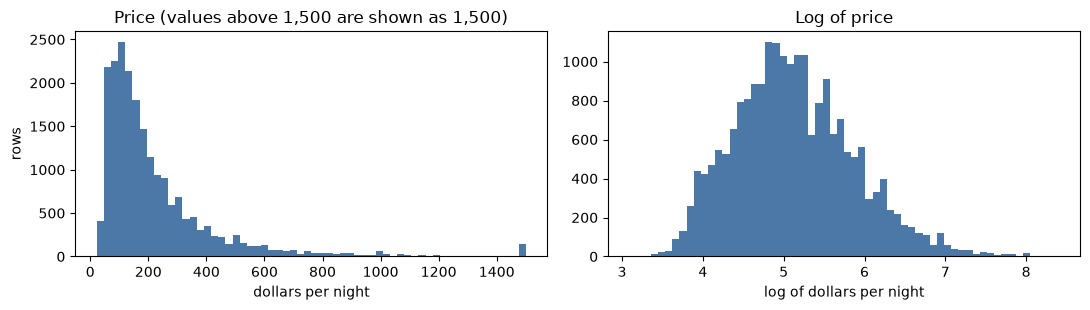

skewness of price: 5.1   of log price: 0.50


In [60]:
listings["log_price"] = np.log(listings["price"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(listings["price"].clip(upper=1500), bins=60, color="#4c78a8")
axes[0].set_title("Price (values above 1,500 are shown as 1,500)")
axes[0].set_xlabel("dollars per night")
axes[1].hist(listings["log_price"], bins=60, color="#4c78a8")
axes[1].set_title("Log of price")
axes[1].set_xlabel("log of dollars per night")
axes[0].set_ylabel("rows")
fig.tight_layout()
plt.show()
print(f"skewness of price: {listings['price'].skew():.1f}   of log price: {listings['log_price'].skew():.2f}")

**The model will predict the logarithm of the price.** The price still has a long tail to the right (skewness 5.1), and the log of the price is much more symmetric (0.50), as the right chart shows. It also fits how prices work: \$20 matters a lot for a \$60 room and little for a \$600 home, and in log terms the same percentage difference counts the same. So errors will be measured in percentages: an error of 0.2 in log price is about 20%. The class notebook used log(1 + price), which is almost identical at these prices; I use the plain log. When I report results, I can convert them back to dollars.

### Takeaways from section 6
- **I keep the expensive homes and remove only 48 rows with placeholder-looking prices** (more than 10 times, or less than a tenth of, the typical price of similar listings). The class notebook cut the top 25% instead.
- **The class notebook's cut removed most big homes:** 67% of 3-bedroom, 81% of 4-bedroom and 94% of 5+ bedroom entire homes.
- **What is left:** 20,996 rows and 7,026 listings, with a highest price of \$4,451.
- **The model will predict `log_price`** (the natural log of the price), which is much more symmetric than the price.
- **Limits of my rule:** a real expensive listing just above the line could be removed, and a placeholder just below it could stay. Moving the line from 10 to 8 or 15 times changes about 15 rows.

## 7. Missing values

This section decides what to do with the blank values. A model cannot use a blank, so each one has to be dropped, filled or flagged. I first look at why each column is blank, because the reason decides the right fix.

**What the class notebook did.** It dropped every column with 20% or more blanks, and then filled every remaining blank number with the column median. It calculated those medians on all rows, before splitting the data into training and test sets, so the test rows helped decide the fill values. Earlier, some blanks had also been turned into zeros (section 5).

### 7.1 Which columns have blanks?

In [61]:
numeric = listings.select_dtypes("number")
numeric_missing = numeric.isna().mean()
numeric_missing = numeric_missing[numeric_missing > 0].sort_values(ascending=False)
print(f"numeric columns: {numeric.shape[1]}; with blanks: {len(numeric_missing)}")
numeric_missing.map("{:.1%}".format).to_frame("share blank")

numeric columns: 144; with blanks: 33


,share blank
estimated_revenue_l365d,26.1%
estimated_occupancy_l365d,26.1%
number_of_reviews_ly,26.1%
availability_eoy,26.1%
review_scores_value,17.9%
review_scores_location,17.9%
review_scores_checkin,17.9%
review_scores_cleanliness,17.9%
review_scores_accuracy,17.9%
review_scores_communication,17.9%


**33 numeric columns have blanks, and the blanks come from four different causes.**
1. Four columns are blank for a whole snapshot (26.1% of rows): section 7.2.
2. The review fields (17.9%): section 7.3.
3. The host fields (0.2% to 15.6%): section 7.4.
4. A few rows only (under 1%): `bedrooms`, `beds`, the bathroom columns and the night limits: section 7.5.

Three columns with blanks are not used (`host_listings_count`, `host_total_listings_count` and `bathrooms`, replaced by other columns in section 5), so I leave them alone.

### 7.2 Four columns that are blank for a whole snapshot

In [62]:
STRUCTURAL = ["availability_eoy", "number_of_reviews_ly", "estimated_occupancy_l365d", "estimated_revenue_l365d"]

# is revenue just price times occupancy?
later = listings[listings["snapshot"] != "Dec 2024"]
busy = later[later["estimated_occupancy_l365d"] > 0]
same = ((busy["estimated_revenue_l365d"] / (busy["price"] * busy["estimated_occupancy_l365d"]) - 1).abs() < 0.005).mean()
print(f"rows where revenue = price x occupancy (within 0.5%): {same:.0%} of {len(busy):,}")

listings.groupby("snapshot", observed=True)[STRUCTURAL].apply(lambda g: g.isna().mean()).style.format("{:.0%}")

rows where revenue = price x occupancy (within 0.5%): 100% of 10,659


,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d
snapshot,,,,
Dec 2024,100%,100%,100%,100%
Mar 2025,0%,0%,0%,0%
Jun 2025,0%,0%,0%,0%
Sep 2025,0%,0%,0%,0%


**These four columns do not exist in the Dec 2024 file.** They are blank for every Dec 2024 row (26% of the data) and filled for every other row, so this is a difference in the file format, not random blanks. One of them is also a leak: `estimated_revenue_l365d` equals price times estimated occupancy for every row that has an occupancy (100% of 10,659 rows), so it contains the answer I want to predict.

**Decision: I drop all four.** The revenue column has to go because of the leak. For the other three, filling a quarter of the rows with guessed values would add noise, so I accept losing them.

In [63]:
listings = listings.drop(columns=STRUCTURAL)
print(f"columns left: {listings.shape[1]}")

columns left: 166


### 7.3 Review fields

In [64]:
no_reviews = listings["number_of_reviews"] == 0
review_cols = [c for c in listings.columns if c.startswith("review_scores_")] + ["reviews_per_month"]
print(f"listings with no reviews: {no_reviews.mean():.1%}")
print(f"median price with no reviews: ${listings.loc[no_reviews, 'price'].median():.0f}; with reviews: ${listings.loc[~no_reviews, 'price'].median():.0f}")

# rows where "blank" and "has no reviews" disagree
pd.DataFrame(
    {
        "share blank": listings[review_cols].isna().mean(),
        "rows where blank and no-reviews disagree": [(listings[c].isna() != no_reviews).sum() for c in review_cols],
    }
).style.format({"share blank": "{:.1%}"})

listings with no reviews: 17.9%
median price with no reviews: $200; with reviews: $150


,share blank,rows where blank and no-reviews disagree
review_scores_rating,17.9%,0
review_scores_accuracy,17.9%,2
review_scores_cleanliness,17.9%,2
review_scores_checkin,17.9%,6
review_scores_communication,17.9%,2
review_scores_location,17.9%,6
review_scores_value,17.9%,6
reviews_per_month,17.9%,0


**The review fields are blank because the listing has no reviews: no reviews, no score.** 17.9% of listings have no reviews. The overall rating and `reviews_per_month` are blank for exactly those rows. The other six scores disagree for only 2 to 6 rows (a listing with reviews but one missing score). A listing with no reviews is not ordinary missing data, because its median price is higher (\$200 against \$150), so the blank itself carries information.

**What I do:** `reviews_per_month` becomes 0, which is what it truly means. The scores get a filler value later (section 8), and I add a 0/1 column `no_reviews`, so the model can tell a filler from a real score.

In [65]:
listings["reviews_per_month"] = listings["reviews_per_month"].fillna(0)  # no reviews means zero reviews a month
listings["no_reviews"] = no_reviews.astype(int)

### 7.4 Host fields

In [66]:
host_blank = {
    "host_response_speed": "host_response_missing",
    "acceptance_rate": "acceptance_rate_missing",
    "host_in_sf": "host_location_missing",
    "is_superhost": "superhost_missing",
}
assert listings["host_response_speed"].isna().equals(listings["response_rate"].isna())  # always blank together

rows = {}
for col, flag in host_blank.items():
    blank = listings[col].isna()
    rows[col] = {
        "rows blank": blank.sum(),
        "share blank": blank.mean(),
        "median price when blank": listings.loc[blank, "price"].median(),
        "median price when filled in": listings.loc[~blank, "price"].median(),
    }
    listings[flag] = blank.astype(int)

pd.DataFrame(rows).T.style.format({"rows blank": "{:,.0f}", "share blank": "{:.1%}", "median price when blank": "{:.0f}", "median price when filled in": "{:.0f}"})

,rows blank,share blank,median price when blank,median price when filled in
host_response_speed,"1,663",7.9%,180,157
acceptance_rate,"1,186",5.6%,192,157
host_in_sf,"3,265",15.6%,130,162
is_superhost,496,2.4%,120,160


**Some host fields are blank, and those listings are priced differently.** Listings whose host has no response time have a median price of \$180 against \$157; no acceptance rate, \$192 against \$157; no location, \$130 against \$162; no superhost value, \$120 against \$160. Response time and response rate are always blank together (the code checks this). These differences are descriptive: the blank hosts may simply be different kinds of hosts, so this is not a cause of the price.

Because the blank itself tells the model something, I add one 0/1 column for each: `host_response_missing`, `acceptance_rate_missing`, `host_location_missing` and `superhost_missing`. The numbers are filled in later.

### 7.5 What is left to fill

In [67]:
MISSING_FLAG_COLS = ["no_reviews", *host_blank.values()]
NOT_USED = ["host_listings_count", "host_total_listings_count", "bathrooms"]  # replaced by other columns in section 5

remaining = listings.select_dtypes("number").isna().mean()
remaining = remaining[remaining > 0].sort_values(ascending=False)
FILL_WITH_TRAIN_MEDIAN = [c for c in remaining.index if c not in NOT_USED]

groups = {
    "review scores": [c for c in FILL_WITH_TRAIN_MEDIAN if c.startswith("review_scores_")],
    "host": [c for c in FILL_WITH_TRAIN_MEDIAN if c.startswith("host_") or c in ("response_rate", "acceptance_rate", "is_superhost")],
    "bathrooms": [c for c in FILL_WITH_TRAIN_MEDIAN if "bathroom" in c],
    "bedrooms and beds": [c for c in FILL_WITH_TRAIN_MEDIAN if c in ("bedrooms", "beds")],
    "night limits": [c for c in FILL_WITH_TRAIN_MEDIAN if c.endswith("_nights")],
}
assert sorted(sum(groups.values(), [])) == sorted(FILL_WITH_TRAIN_MEDIAN)  # every column belongs to exactly one group
assert all(listings[c].dtype.kind in "iuf" for c in FILL_WITH_TRAIN_MEDIAN + MISSING_FLAG_COLS)

pd.DataFrame(
    {g: {"columns": len(cols), "rows blank (largest)": listings[cols].isna().sum().max(), "share blank (largest)": listings[cols].isna().mean().max()} for g, cols in groups.items()}
).T.astype({"columns": int, "rows blank (largest)": int}).style.format({"share blank (largest)": "{:.2%}"})

,columns,rows blank (largest),share blank (largest)
review scores,7,3759,17.90%
host,9,3265,15.55%
bathrooms,3,25,0.12%
bedrooms and beds,2,88,0.42%
night limits,4,4,0.02%


**25 columns still have blanks, with at most 17.9% blank** (review scores) **and 15.6%** (host). The rest are tiny: `bedrooms` has 88 blank rows (0.4%), `beds` 83, the bathroom columns 25 and the night limits 4. These are too few to matter, so they get no flag.

**I do not fill them now.** The fill value will be the median of the *training* data only, calculated in section 8 after the split, so that no information from the test rows reaches the model. The class notebook calculated the medians on all rows first, so the test rows influenced the fill values. The difference in the numbers is probably small, but the test set should stay unseen. The lists `FILL_WITH_TRAIN_MEDIAN` and `MISSING_FLAG_COLS` carry this plan into section 8. The five flag columns can be built now, because they need no fitting.

### Takeaways from section 7
- **33 numeric columns have blanks, from four different causes,** and I choose the fix by the cause.
- **I drop four columns that are blank for all of Dec 2024.** One of them, `estimated_revenue_l365d`, is price times occupancy, so it would leak the answer.
- **Review blanks mean "no reviews".** `reviews_per_month` becomes 0, and the new column `no_reviews` flags the rest.
- **Host blanks come with different prices,** so I add four 0/1 flag columns (`host_response_missing`, `acceptance_rate_missing`, `host_location_missing`, `superhost_missing`).
- **25 columns still have blanks (at most 17.9%).** I fill them in section 8 with medians from the training data only, so the test rows stay unseen. The class notebook used all rows.

## 8. Evaluation design and models

This section tests how well the price can be predicted for hosts the model has never seen, and compares four models against two baselines.

**What the class notebook did.** It split the rows 70/30 at random, after removing `id` and `host_id`, so it could not keep a listing or a host on one side. It also filled the blanks on all rows before splitting (section 7). It compared linear regression (on PCA components), a shallow decision tree, a random forest and gradient boosting, tuned with a random 5-fold split.

**How I do it.**
1. I split the data by host, so no host and no listing is on both the training side and the test side.
2. I assemble the model inputs and check that none of them contains the answer.
3. I tune four models on the training data only, and keep the test data for one final check.
4. I show how much a random split of rows would flatter the score.
5. I repeat the split five times to see how stable the result is.

### 8.1 Splitting the data by host

In [68]:
from functools import partial

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# connect every listing to every host it has had; each connected piece is one group that must stay together
host_node, host_idx = np.unique(listings["host_id"], return_inverse=True)
listing_node, listing_idx = np.unique(listings["id"], return_inverse=True)
n_hosts = len(host_node)
links = coo_matrix((np.ones(len(listings)), (host_idx, n_hosts + listing_idx)), shape=(n_hosts + len(listing_node),) * 2)
_, node_group = connected_components(links, directed=False)
group = pd.Series(node_group[host_idx], index=listings.index, name="group")

group_rows = group.value_counts()
print(f"hosts: {n_hosts:,}   listings: {len(listing_node):,}   groups: {group.nunique():,}")
print(f"groups that join more than one host (a listing changed host): {(listings.groupby(group)['host_id'].nunique() > 1).sum()}")
print(f"largest group: {group_rows.iloc[0]} rows ({group_rows.iloc[0] / len(listings):.1%})")

hosts: 3,762   listings: 7,026   groups: 3,735
groups that join more than one host (a listing changed host): 23
largest group: 650 rows (3.1%)


In [69]:
train_pos, test_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED).split(listings, groups=group))
train, test = listings.iloc[train_pos], listings.iloc[test_pos]
assert not set(train["host_id"]) & set(test["host_id"])  # no host on both sides
assert not set(train["id"]) & set(test["id"])  # no listing on both sides

pd.DataFrame(
    {
        name: {
            "rows": len(part),
            "share of rows": len(part) / len(listings),
            "hosts": part["host_id"].nunique(),
            "listings": part["id"].nunique(),
            "median price": part["price"].median(),
            "share entire homes": (part["room_type"] == "Entire home/apt").mean(),
        }
        for name, part in {"training": train, "test": test}.items()
    }
).T.style.format({"rows": "{:,.0f}", "share of rows": "{:.0%}", "hosts": "{:,.0f}", "listings": "{:,.0f}", "median price": "{:.0f}", "share entire homes": "{:.0%}"})

,rows,share of rows,hosts,listings,median price,share entire homes
training,"15,548",74%,"2,633","5,184",160,73%
test,"5,448",26%,"1,129","1,842",157,72%


**Why by host.** Sections 3.3 and 3.4 showed two reasons. The same listing appears up to four times, and one host often has several near-identical listings. If one copy is in training and its twin is in the test, the model has already seen the answer.

**How I build the groups.** I connect every listing to every host it has had. 3,762 hosts and 7,026 listings form 3,735 groups. 23 groups join two or more hosts, because a listing changed host: this keeps both hosts and the listing together. The largest group has 650 rows (3.1%). Then I put 30% of the groups at random into the test set. The test set gets 26% of the rows, because groups are drawn by count and the big hosts are not drawn evenly. The two sides look alike (median price \$160 and \$157, entire homes 73% and 72%), and the code checks that no host and no listing is on both sides.

### 8.2 The model inputs

In [70]:
REVIEW_SCORES = [c for c in listings.columns if c.startswith("review_scores_")]
RAW_NUMBERS = [
    "accommodates", "bedrooms", "beds", "latitude", "longitude",
    "availability_30", "availability_60", "availability_90", "availability_365",
    "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d", "reviews_per_month", *REVIEW_SCORES,
]
MODEL_GROUPS = {**FEATURE_GROUPS, "raw numbers (size, coordinates, availability, reviews)": RAW_NUMBERS, "blank flags (section 7)": MISSING_FLAG_COLS}
FEATURES = [c for cols in MODEL_GROUPS.values() for c in cols]

assert len(FEATURES) == len(set(FEATURES)), "a column is listed twice"
assert not {"price", "log_price", "id", "host_id"} & set(FEATURES)
assert not any("revenue" in c for c in FEATURES)  # the leak dropped in section 7
assert set(listings[FEATURES].columns[listings[FEATURES].isna().any()]) <= set(FILL_WITH_TRAIN_MEDIAN)  # every blank has a fill plan

# a linear model cannot use all columns of a 0/1 group (they add up to 1): leave out the most common one in each
ONE_HOT = {
    "season": SEASON_COLS,
    "building type": BUILDING_COLS,
    "neighbourhood": NEIGHBOURHOOD_COLS,
    "license": [c for c in HOST_COLS if c.startswith("license_")],
}
LEFT_OUT_FOR_LINEAR = [listings[cols].sum().idxmax() for cols in ONE_HOT.values()]
LINEAR_FEATURES = [c for c in FEATURES if c not in LEFT_OUT_FOR_LINEAR]

print(f"{len(FEATURES)} model inputs ({len(LINEAR_FEATURES)} for the linear model, which leaves out {LEFT_OUT_FOR_LINEAR})")
pd.Series({group_name: len(cols) for group_name, cols in MODEL_GROUPS.items()}, name="columns").to_frame()

128 model inputs (124 for the linear model, which leaves out ['snap_dec_2024', 'building_rental unit', 'nbhd_mission', 'license_registered'])


,columns
season (section 2),4
room and building type (section 4),9
distances (section 1),3
host,17
amenities,29
neighbourhood,36
bathrooms,3
stay length,2
"raw numbers (size, coordinates, availability, reviews)",20
blank flags (section 7),5


**128 model inputs in ten groups.** They are the groups built in sections 1 to 7, plus the raw numbers that need no building (guests, bedrooms, beds, coordinates, availability, review counts and scores) and the five flag columns from section 7. I leave out the four minimum/maximum-night variants, because `minimum_nights` and `maximum_nights_capped` already describe the stay limits.

**Checks in the code:** no column is listed twice, `price`, `log_price`, `id` and `host_id` are not inputs, no input has "revenue" in its name (the leak removed in section 7), and every blank has a fill plan from section 7. The linear model cannot use all columns of a 0/1 group (they add up to 1), so it leaves out the most common one in each group: December 2024, rental unit, Mission and registered license. That gives it 124 inputs.

**A note on reviews and availability.** I keep them as inputs. They are known facts about a listing today, but they may partly reflect how well the price has worked, so I will treat them with care in section 9.

### 8.3 The models

In [71]:
X_train, y_train, g_train = train[FEATURES], train["log_price"], group.loc[train.index]
X_test, y_test = test[FEATURES], test["log_price"]
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)  # for tuning: whole groups stay together inside the training data


def fill_then(model, scale=False):
    """The blanks are filled with medians learned from the rows the model is trained on, never from the test rows."""
    steps = [("fill", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else []) + [("model", model)]
    return Pipeline(steps)


def tune(pipeline, params, features, n_iter=None):
    search_class = GridSearchCV if n_iter is None else partial(RandomizedSearchCV, n_iter=n_iter, random_state=SEED)
    search = search_class(pipeline, params, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    return search.fit(X_train[features], y_train, groups=g_train)


from sklearn.base import BaseEstimator, RegressorMixin


class LookupTable(BaseEstimator, RegressorMixin):
    """A plain table, no machine learning: the median log price of the training listings in the same
    neighbourhood, room type and bedroom count. If that group has fewer than min_rows listings, it falls
    back to a broader group (room type and bedrooms, then room type, then everything)."""

    def __init__(self, min_rows=10):
        self.min_rows = min_rows

    def _keys(self, X):
        return pd.DataFrame(
            {
                "area": X[NEIGHBOURHOOD_COLS].idxmax(axis=1),
                "room": np.where(X["is_entire_home"] == 1, "entire", "private"),
                "beds": X["bedrooms"].clip(upper=4).fillna(-1).astype(int),  # 4 = 4 or more, -1 = unknown
            },
            index=X.index,
        )

    def fit(self, X, y):
        keys = self._keys(X)
        self.levels_ = [["area", "room", "beds"], ["room", "beds"], ["room"]]
        self.tables_ = []
        for cols in self.levels_:
            stats = y.groupby([keys[c] for c in cols]).agg(["median", "size"])
            self.tables_.append(stats.loc[stats["size"] >= self.min_rows, "median"])
        self.overall_ = y.median()
        return self

    def predict(self, X):
        keys = self._keys(X)
        prediction = pd.Series(np.nan, index=X.index)
        for cols, table in zip(self.levels_, self.tables_):
            found = table.reindex(pd.MultiIndex.from_frame(keys[cols]) if len(cols) > 1 else pd.Index(keys[cols[0]]))
            prediction = prediction.fillna(pd.Series(found.to_numpy(), index=X.index))
        return prediction.fillna(self.overall_).to_numpy()


models = {}  # name -> (fitted pipeline, columns it uses)
models["Always the median price"] = (fill_then(DummyRegressor(strategy="median")).fit(X_train, y_train), FEATURES)
models["Lookup table (median of similar listings)"] = (LookupTable().fit(X_train, y_train), FEATURES)
searches = {
    "Linear regression (ridge)": (tune(fill_then(Ridge(), scale=True), {"model__alpha": [0.1, 1, 10, 100, 1000]}, LINEAR_FEATURES), LINEAR_FEATURES),
    "Decision tree": (tune(fill_then(DecisionTreeRegressor(random_state=SEED)), {"model__max_depth": [3, 5, 8, 12], "model__min_samples_leaf": [10, 30]}, FEATURES), FEATURES),
    "Random forest": (
        tune(
            fill_then(RandomForestRegressor(n_estimators=200, n_jobs=1, random_state=SEED)),
            {"model__max_features": [0.2, 0.33, 0.5], "model__min_samples_leaf": [1, 3, 5], "model__max_depth": [None, 25]},
            FEATURES,
            n_iter=6,
        ),
        FEATURES,
    ),
    "Gradient boosting": (
        tune(
            fill_then(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),
            {"model__learning_rate": [0.03, 0.06, 0.1], "model__max_leaf_nodes": [15, 31], "model__max_iter": [200, 400], "model__l2_regularization": [0, 1, 10]},
            FEATURES,
            n_iter=8,
        ),
        FEATURES,
    ),
}
for name, (search, features) in searches.items():
    models[name] = (search.best_estimator_, features)

pd.DataFrame(
    {name: {"chosen settings": {k.replace("model__", ""): v for k, v in s.best_params_.items()}, "cross-validated RMSE (log price)": -s.best_score_} for name, (s, _) in searches.items()}
).T.style.format({"cross-validated RMSE (log price)": "{:.3f}"})

/Users/yho/code/airbnb/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,chosen settings,cross-validated RMSE (log price)
Linear regression (ridge),{'alpha': 100},0.378
Decision tree,"{'max_depth': 12, 'min_samples_leaf': 30}",0.448
Random forest,"{'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': None}",0.371
Gradient boosting,"{'max_leaf_nodes': 31, 'max_iter': 400, 'learning_rate': 0.03, 'l2_regularization': 10}",0.354


**Six predictors, from simplest to strongest.**
- **Always the median price (the simplest baseline):** no model. It predicts the same price for every listing, the median of the training prices, and uses nothing about the listing. Every other model has to beat it, and the comparison shows how much the best model really adds. It scores an R² of about 0 by definition.
- **Lookup table (a stronger baseline):** no machine learning, just a table. It predicts the median price of the training listings in the same neighbourhood, room type and bedroom count (or a broader group when there are fewer than 10 such listings).
- **Linear regression (ridge):** adds up each input times a weight. Ridge shrinks the weights, which keeps them stable.
- **Decision tree:** a chain of yes/no questions (for example "more than 2 bedrooms?") that ends in a price.
- **Random forest:** many decision trees, each trained on a different sample, with their answers averaged.
- **Gradient boosting:** trees built one after another, each one correcting the mistakes of the ones before.

**Tuning uses the training data only.** I pick each model's settings with 5-fold cross-validation inside the training data, where whole groups stay together. The blanks are filled with medians learned from the rows the model trains on (the plan from section 7), inside the same pipeline, so the test rows never touch the fill values. Gradient boosting has the lowest error in this tuning (0.354 in log price).

### 8.4 Results on the test hosts

In [72]:
def errors(pred, actual):
    """Several ways to say how far off the predictions are (prices are on the log scale)."""
    diff = pred - actual
    return {
        "RMSE (log price)": np.sqrt(np.mean(diff**2)),
        "R2": r2_score(actual, pred),
        "typical error (median)": np.median(np.abs(np.exp(diff) - 1)),
        "within 20% of the real price": np.mean(np.abs(np.exp(diff) - 1) <= 0.2),
        "typical error in dollars (median)": np.median(np.abs(np.exp(pred) - np.exp(actual))),
    }


# 95% interval for R2 from resampling whole groups of test rows (rows of one host are not independent)
rng = np.random.default_rng(SEED)
test_group = group.loc[test.index].to_numpy()
members = [np.flatnonzero(test_group == g) for g in np.unique(test_group)]
resamples = [np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))]) for _ in range(500)]

rows = {}
predictions = {}
for name, (pipeline, features) in models.items():
    pred = pipeline.predict(X_test[features])
    predictions[name] = pred
    low, high = np.percentile([r2_score(y_test.to_numpy()[i], pred[i]) for i in resamples], [2.5, 97.5])
    rows[name] = {**errors(pred, y_test.to_numpy()), "R2 low": low, "R2 high": high}
results = pd.DataFrame(rows).T
results.style.format(
    {"RMSE (log price)": "{:.3f}", "R2": "{:.3f}", "R2 low": "{:.3f}", "R2 high": "{:.3f}", "typical error (median)": "{:.0%}", "within 20% of the real price": "{:.0%}", "typical error in dollars (median)": "{:.0f}"}
)

,RMSE (log price),R2,typical error (median),within 20% of the real price,typical error in dollars (median),R2 low,R2 high
Always the median price,0.724,-0.003,45%,25%,70,-0.021,-0.000
Lookup table (median of similar listings),0.498,0.525,28%,36%,41,0.448,0.590
Linear regression (ridge),0.391,0.708,22%,47%,33,0.636,0.761
Decision tree,0.435,0.638,24%,43%,36,0.589,0.678
Random forest,0.353,0.761,20%,49%,30,0.709,0.796
Gradient boosting,0.337,0.782,19%,52%,29,0.733,0.815


**Gradient boosting is the best model on the test hosts, with an R² of 0.78.** R² is the share of the differences in log price that the model explains: 0 means no better than always guessing the median, 1 means perfect.

| Model | R² | Typical error | Within 20% of the real price |
|---|---|---|---|
| Always the median price | 0.00 | 45% | 25% |
| Lookup table (median of similar listings) | 0.52 | 28% | 36% |
| Decision tree | 0.64 | 24% | 43% |
| Linear regression (ridge) | 0.71 | 22% | 47% |
| Random forest | 0.76 | 20% | 49% |
| Gradient boosting | 0.78 | 19% | 52% |

In dollars, the typical miss is about \$29 for gradient boosting, against \$41 for the lookup table and \$70 for always guessing the median. The 95% interval for the R² of gradient boosting is 0.73 to 0.82. It comes from resampling whole hosts of the test set, because rows of one host are not independent. The intervals of gradient boosting and the random forest overlap a lot, so this single split cannot show that one is truly better than the other (see 8.6).

**The best model against the baselines.** I use two baselines that involve no machine learning. The simplest predicts the same price for every listing (the median of the training prices). The stronger one is a lookup table: the median price of similar listings (same neighbourhood, room type and bedrooms). Gradient boosting beats both clearly: R² 0.78 against 0.00 and 0.52; a typical error of 19% against 45% and 28%; a typical miss of \$29 against \$70 and \$41; and 52% of the listings within 20% of the real price against 25% and 36%. The lookup table alone already explains about half of the differences in price (R² 0.52), so a plain table is a hard baseline to beat. The simple linear model (R² 0.71) gets most of the rest, and the more complex models add about 0.07 on top.

In [73]:
best = results["R2"].idxmax()
columns = {
    "baseline 1: always the median price": results.loc["Always the median price"],
    "baseline 2: lookup table": results.loc["Lookup table (median of similar listings)"],
    f"best model: {best}": results.loc[best],
}
formats = {
    "R2": ("R2", "{:.2f}"),
    "error in log price (RMSE)": ("RMSE (log price)", "{:.2f}"),
    "typical error": ("typical error (median)", "{:.0%}"),
    "within 20% of the real price": ("within 20% of the real price", "{:.0%}"),
    "typical miss in dollars": ("typical error in dollars (median)", "${:.0f}"),
}
# the median baseline has an R2 of -0.003, shown as 0.00
pd.DataFrame(
    {title: {measure: fmt.format(round(row[key], 2) + 0.0 if key == "R2" else row[key]) for measure, (key, fmt) in formats.items()} for title, row in columns.items()}
)

,baseline 1: always the median price,baseline 2: lookup table,best model: Gradient boosting
R2,0.00,0.52,0.78
error in log price (RMSE),0.72,0.50,0.34
typical error,45%,28%,19%
within 20% of the real price,25%,36%,52%
typical miss in dollars,$70,$41,$29


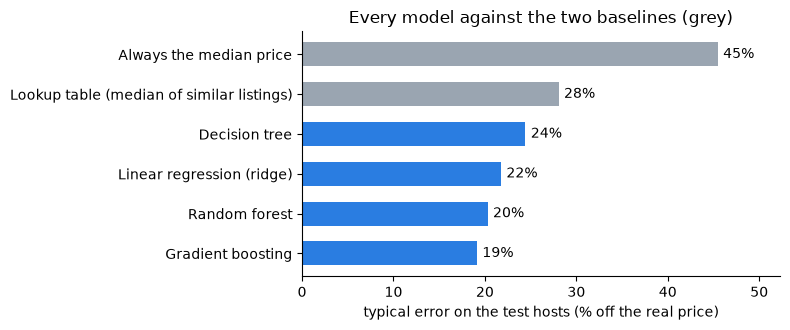

In [74]:
typical = results["typical error (median)"].sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.barh(typical.index, typical.values, color=["#9aa5b1" if m in ("Always the median price", "Lookup table (median of similar listings)") else "#2a7de1" for m in typical.index], height=0.6)
for bar, value in zip(bars, typical.values):
    ax.text(value + 0.6, bar.get_y() + bar.get_height() / 2, f"{value:.0f}%", va="center")
ax.invert_yaxis()
ax.set_xlim(0, typical.max() * 1.15)
ax.set_xlabel("typical error on the test hosts (% off the real price)")
ax.set_title("Every model against the two baselines (grey)")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

### 8.5 Why the split matters

In [75]:
# the same random forest, trained and tested twice: once with a random split of rows, once with the split by host
forest = clone(models["Random forest"][0]).set_params(model__n_jobs=-1)
random_train, random_test = train_test_split(np.arange(len(listings)), test_size=0.3, random_state=SEED)
by_host = {"random rows (how the class notebook split)": (random_train, random_test), "by host (this notebook)": (train_pos, test_pos)}

pd.DataFrame(
    {
        name: {
            "test R2": r2_score(listings["log_price"].iloc[te], clone(forest).fit(listings[FEATURES].iloc[tr], listings["log_price"].iloc[tr]).predict(listings[FEATURES].iloc[te])),
            "test hosts also in training": len(set(listings["host_id"].iloc[te]) & set(listings["host_id"].iloc[tr])) / listings["host_id"].iloc[te].nunique(),
            "test listings also in training": len(set(listings["id"].iloc[te]) & set(listings["id"].iloc[tr])) / listings["id"].iloc[te].nunique(),
        }
        for name, (tr, te) in by_host.items()
    }
).T.style.format({"test R2": "{:.3f}", "test hosts also in training": "{:.0%}", "test listings also in training": "{:.0%}"})

,test R2,test hosts also in training,test listings also in training
random rows (how the class notebook split),0.908,91%,88%
by host (this notebook),0.761,0%,0%


**A random split of rows flatters the score a lot.** The same random forest scores an R² of 0.91 when I split rows at random, and 0.76 when I split by host. In the random split, 91% of the test hosts and 88% of the test listings also appear in the training data, so the model is partly tested on listings it has already seen (another snapshot of the same listing, or its twin). The difference of 0.15 is leakage, not skill. I cannot compare my numbers with the class notebook's score, because its data was cut differently (section 6), but the same effect probably inflated it.

### 8.6 Is the result stable?

In [76]:
# the same chosen settings, trained and tested on five different host splits
stability = {}
for seed in range(1, 6):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed).split(listings, groups=group))
    stability[seed] = {
        name: r2_score(listings["log_price"].iloc[te], clone(pipeline).set_params(**({"model__n_jobs": -1} if name == "Random forest" else {})).fit(listings[features].iloc[tr], listings["log_price"].iloc[tr]).predict(listings[features].iloc[te]))
        for name, (pipeline, features) in models.items()
        if name != "Always the median price"
    }
stability = pd.DataFrame(stability).T
pd.DataFrame({"mean": stability.mean(), "lowest": stability.min(), "highest": stability.max()}).style.format("{:.3f}")

,mean,lowest,highest
Lookup table (median of similar listings),0.528,0.477,0.558
Linear regression (ridge),0.722,0.637,0.771
Decision tree,0.651,0.590,0.698
Random forest,0.747,0.671,0.793
Gradient boosting,0.772,0.695,0.819


**The order of the models is stable on average, but the numbers move.** Over five different host splits, gradient boosting averages 0.77 (from 0.70 to 0.82), the random forest 0.75 (0.67 to 0.79), ridge 0.72 (0.64 to 0.77), the decision tree 0.65 (0.59 to 0.70) and the lookup table 0.53 (0.48 to 0.56). Which hosts land in the test set changes the R² by about 0.06 either way, which is more than the gap between gradient boosting and the random forest (0.03 on average). So I treat these two as close, and I trust the single-split number of 0.78 only as one draw from this range.

### Takeaways from section 8
- **I split by host and keep every listing together:** 15,548 training rows and 5,448 test rows. No host and no listing is on both sides.
- **128 model inputs,** checked for leaks. The blanks are filled with training medians inside the pipeline, as planned in section 7.
- **Gradient boosting is the best model, and it beats both baselines by a wide margin:** R² 0.78 on the test hosts against 0.00 for always guessing the median price and 0.52 for a plain lookup table, a typical error of 19% (about \$29) against 45% (about \$70) and 28% (about \$41), and 52% of the listings within 20% of the real price against 25% and 36%. The random forest (0.76) is close; ridge regression (0.71) and the decision tree (0.64) are further behind.
- **The split matters:** the same random forest scores 0.91 with a random split of rows and 0.76 with a split by host.
- **The result moves by about 0.06 depending on which hosts are in the test set,** so I do not read much into small gaps between models.
- **Limits:** the prices are asking prices, the data covers one year and four dates, and the test hosts come from the same market and the same four dates, so the score says nothing about a new city or a new season.

## 9. Results and drivers

This section explains what the best model learned: which inputs drive the price, how good the predictions are, and where they fail. It also runs three checks on claims I am about to make. I use the best model from section 8, gradient boosting, and the 1,129 test hosts it never saw.

### 9.1 What matters most

In [77]:
from pathlib import Path

best_name = "Gradient boosting"
best_model = models[best_name][0]
y_all = listings["log_price"]

DRIVER_GROUPS = {
    "Size and type": ["accommodates", "bedrooms", "beds", "is_entire_home", *BUILDING_COLS, *BATHROOM_COLS],
    "Location": [*NEIGHBOURHOOD_COLS, "latitude", "longitude", *DISTANCE_COLS],
    "Host and license": [*HOST_COLS, *[c for c in MISSING_FLAG_COLS if c != "no_reviews"]],
    "Amenities": AMENITY_COLS,
    "Reviews and availability": [c for c in RAW_NUMBERS if c.startswith(("availability", "number_of_reviews", "reviews_per", "review_scores"))] + ["no_reviews"],
    "Stay length": ["minimum_nights", "maximum_nights_capped"],
    "Time of year": SEASON_COLS,
}
assert sorted(sum(DRIVER_GROUPS.values(), [])) == sorted(FEATURES)  # every input is in exactly one group


def score_drop(columns, repeats=10):
    """How much the R2 on the test hosts falls when these columns are scrambled together (same shuffle for all of them)."""
    rng = np.random.default_rng(SEED)
    base = r2_score(y_test, best_model.predict(X_test))
    drops = []
    for _ in range(repeats):
        scrambled = X_test.copy()
        scrambled[columns] = X_test[columns].to_numpy()[rng.permutation(len(X_test))]
        drops.append(base - r2_score(y_test, best_model.predict(scrambled)))
    return np.mean(drops), np.std(drops)


drivers = pd.DataFrame({g: score_drop(cols) for g, cols in DRIVER_GROUPS.items()}, index=["drop in R2", "spread"]).T.sort_values("drop in R2", ascending=False)
drivers["columns"] = [len(DRIVER_GROUPS[g]) for g in drivers.index]
print(f"R2 of {best_name} on the test hosts: {r2_score(y_test, best_model.predict(X_test)):.3f}")
drivers.style.format({"drop in R2": "{:.3f}", "spread": "{:.3f}"})

R2 of Gradient boosting on the test hosts: 0.782


,drop in R2,spread,columns
Size and type,0.836,0.013,15
Location,0.127,0.003,41
Stay length,0.114,0.003,2
Reviews and availability,0.090,0.004,16
Host and license,0.034,0.002,21
Amenities,0.028,0.002,29
Time of year,0.010,0.001,4


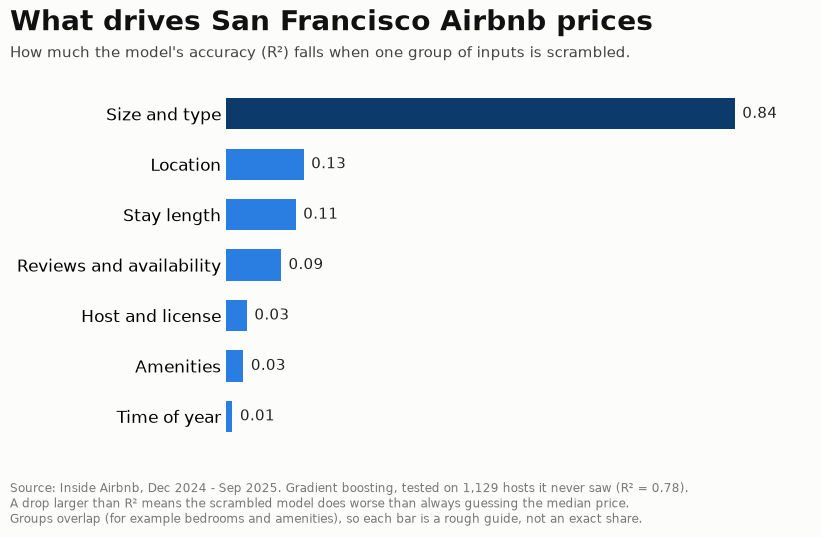

In [78]:
# the picture for the project: the same numbers as a chart
plot_data = drivers["drop in R2"].sort_values()
fig, ax = plt.subplots(figsize=(9, 5.4), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
bars = ax.barh(plot_data.index, plot_data.values, color=["#0b3a6b" if v == plot_data.max() else "#2a7de1" for v in plot_data.values], height=0.62)
for bar, value in zip(bars, plot_data.values):
    ax.text(value + plot_data.max() * 0.015, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center", fontsize=11, color="#222")
ax.set_xlim(0, plot_data.max() * 1.15)
ax.set_xticks([])
ax.tick_params(axis="y", length=0, labelsize=12)
for side in ("top", "right", "bottom", "left"):
    ax.spines[side].set_visible(False)
fig.text(0.06, 0.945, "What drives San Francisco Airbnb prices", fontsize=20, fontweight="bold", color="#111")
fig.text(0.06, 0.895, "How much the model's accuracy (R²) falls when one group of inputs is scrambled.", fontsize=11, color="#444")
fig.text(0.06, 0.025, f"Source: Inside Airbnb, Dec 2024 - Sep 2025. Gradient boosting, tested on {test['host_id'].nunique():,} hosts it never saw (R² = {r2_score(y_test, best_model.predict(X_test)):.2f}).\nA drop larger than R² means the scrambled model does worse than always guessing the median price.\nGroups overlap (for example bedrooms and amenities), so each bar is a rough guide, not an exact share.", fontsize=8.5, color="#777", va="bottom")
fig.subplots_adjust(left=0.3, right=0.95, top=0.85, bottom=0.17)
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/sf_airbnb_price_drivers.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()

**The size and type of the place matters far more than anything else.** To measure this, I scramble one group of columns among the test listings (so the values no longer match the right listing) and see how much the R² falls. Scrambling size and type drops it by 0.84, which is more than the model's whole R² of 0.78: the scrambled model does worse than always guessing the median price. Next come location (0.13), stay length (0.11) and reviews and availability (0.09). Host and license (0.03), amenities (0.03) and time of year (0.01) matter little.

**How to read this.** The bars show how much the model relies on a group, not a share of the price. The groups overlap (bigger places also have more amenities), so each bar is a rough guide. The chart above shows these numbers.

In [79]:
single = pd.Series({c: score_drop([c], repeats=5)[0] for c in FEATURES}).sort_values(ascending=False)
single.head(12).to_frame("drop in R2").style.format("{:.3f}")

,drop in R2
accommodates,0.135
is_entire_home,0.111
minimum_nights,0.106
private_bathrooms,0.058
latitude,0.051
bedrooms,0.049
distance_to_attraction_km,0.021
longitude,0.013
review_scores_cleanliness,0.011
reviews_per_month,0.008


**Looking at single inputs,** the biggest are the number of guests the place fits (0.14), whether it is an entire home or a private room (0.11), the minimum stay (0.11), private bathrooms (0.06), latitude (0.05) and bedrooms (0.05). Location is spread over many columns (36 neighbourhoods, coordinates, three distances), so no single location column is large, but together they matter (0.13). I do not know why the minimum stay matters as much as entire home versus private room. Long minimum stays are probably priced differently (monthly rentals) or belong to a different kind of listing, but I did not test that, and none of this shows a cause.

### 9.2 How good are the predictions?

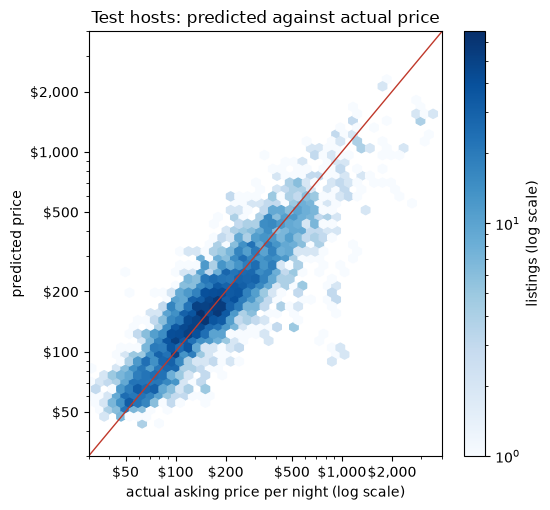

In [80]:
pred_test = predictions[best_name]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
hexes = ax.hexbin(np.exp(y_test), np.exp(pred_test), xscale="log", yscale="log", gridsize=45, bins="log", cmap="Blues", mincnt=1)
ax.plot([30, 4000], [30, 4000], color="#c0392b", lw=1)
ax.set_xlim(30, 4000)
ax.set_ylim(30, 4000)
ticks = [50, 100, 200, 500, 1000, 2000]
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(plt.FixedLocator(ticks))
    axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    axis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("actual asking price per night (log scale)")
ax.set_ylabel("predicted price")
ax.set_title("Test hosts: predicted against actual price")
fig.colorbar(hexes, label="listings (log scale)")
fig.tight_layout()
plt.show()

**The predictions follow the real prices closely, with a wide spread.** The gradient boosting model has an R² of 0.78 on the test hosts. Its typical error is 19% (about \$29), and 52% of the listings are predicted within 20% of the real price. In the chart, the points follow the red line (a perfect prediction), but the cloud is wide, and at both ends it bends towards the middle (see 9.6).

### 9.3 Season

In [81]:
def predicted_change_if_snapshot(label):
    """Average change in the predicted price if every test row were seen on this snapshot instead of Dec 2024."""
    def predict_as(snapshot):
        X = X_test.copy()
        for s in SNAPSHOTS:
            X["snap_" + s.lower().replace(" ", "_")] = int(s == snapshot)
        return best_model.predict(X)
    return np.expm1(np.mean(predict_as(label) - predict_as("Dec 2024")))


pd.DataFrame(
    {
        "model: predicted change vs Dec 2024": {s: predicted_change_if_snapshot(s) for s in SNAPSHOTS},
        "section 2: same listings, trimmed mean": {"Dec 2024": 0.0, "Mar 2025": 0.021, "Jun 2025": 0.105, "Sep 2025": 0.104},
    }
).style.format("{:+.1%}")

,model: predicted change vs Dec 2024,"section 2: same listings, trimmed mean"
Dec 2024,+0.0%,+0.0%
Mar 2025,+2.2%,+2.1%
Jun 2025,+10.3%,+10.5%
Sep 2025,+9.8%,+10.4%


**The model finds the same season effect as section 2.** If every test listing were seen in a later snapshot, the model predicts prices about 2% higher in Mar 2025, 10% in Jun 2025 and 10% in Sep 2025, against Dec 2024. Section 2 measured +2.1%, +10.5% and +10.4% on the same listings across time, so the two methods agree. Season is a small driver (0.01 in 9.1). As in section 2, one year of data cannot separate a seasonal pattern from a general rise in asking prices, so I do not call this seasonality.

### 9.4 Do the distance features help?

In [82]:
five_splits = [next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed).split(listings, groups=group)) for seed in range(1, 6)]


def r2_over_splits(drop_columns):
    """Test R2 of the best model on the five host splits from 8.6, trained without the given columns."""
    columns = [c for c in FEATURES if c not in drop_columns]
    return np.array(
        [
            r2_score(y_all.iloc[te], clone(best_model).fit(listings[columns].iloc[tr], y_all.iloc[tr]).predict(listings[columns].iloc[te]))
            for tr, te in five_splits
        ]
    )


with_all = r2_over_splits([])


def without(columns):
    gap = with_all - r2_over_splits(columns)
    return {"columns removed": len(columns), "R2 lost (mean of 5 splits)": gap.mean(), "smallest loss": gap.min(), "largest loss": gap.max()}


distance_checks = pd.DataFrame(
    {
        "all three distances": without(DISTANCE_COLS),
        "BART distance only": without(["distance_to_bart_km"]),
        "Muni distance only": without(["distance_to_muni_km"]),
        "attraction distance only": without(["distance_to_attraction_km"]),
        "all location inputs": without(DRIVER_GROUPS["Location"]),
    }
).T
distance_checks.style.format({"R2 lost (mean of 5 splits)": "{:.3f}", "smallest loss": "{:.3f}", "largest loss": "{:.3f}"})

,columns removed,R2 lost (mean of 5 splits),smallest loss,largest loss
all three distances,3.000000,-0.001,-0.002,0.002
BART distance only,1.000000,0.002,-0.002,0.006
Muni distance only,1.000000,-0.002,-0.006,0.002
attraction distance only,1.000000,0.000,-0.003,0.003
all location inputs,41.000000,0.029,0.020,0.036


**The three distance features add nothing the model cannot get elsewhere.** I train the model again without them on the five host splits from 8.6. Without all three distances, the R² changes by -0.001 (no loss), and removing any one of them changes it by 0.002 or less. Removing all 41 location inputs (neighbourhoods, coordinates and distances) costs 0.029. This differs from the 0.13 in 9.1: scrambling shows how much the trained model relies on location, while retraining lets other inputs (such as the neighbourhood, the coordinates and the review score for location) fill in. So location matters, but the distances are redundant, because the coordinates already carry the same information. The distances to BART, Muni and attractions can be dropped without losing accuracy. I keep them as inputs, but I would not claim that transit or sights drive the price.

### 9.5 Do reviews and availability carry the score?

In [83]:
review_group = DRIVER_GROUPS["Reviews and availability"]
review_checks = pd.DataFrame(
    {
        "reviews and availability": without(review_group),
        "reviews only": without([c for c in review_group if not c.startswith("availability")]),
        "availability only": without([c for c in review_group if c.startswith("availability")]),
    }
).T
print(f"R2 with everything, mean of 5 splits: {with_all.mean():.3f}")
review_checks.style.format({"R2 lost (mean of 5 splits)": "{:.3f}", "smallest loss": "{:.3f}", "largest loss": "{:.3f}"})

R2 with everything, mean of 5 splits: 0.772


,columns removed,R2 lost (mean of 5 splits),smallest loss,largest loss
reviews and availability,16.000000,0.035,0.022,0.044
reviews only,12.000000,0.018,0.012,0.026
availability only,4.000000,0.013,0.007,0.019


**The score does not rest mainly on reviews and availability.** Without all 16 of these columns, the R² falls from 0.772 to 0.737, a loss of 0.035 (between 0.022 and 0.044 over five splits). Reviews alone cost 0.018 and availability alone 0.013. So even if all of that loss were leakage (I cannot tell how much is), it would be small next to the whole score. I still keep them in the model, because they are known facts about a listing today.

### 9.6 Where is the model wrong?

In [84]:
view = test.assign(predicted=np.exp(pred_test), error=np.exp(pred_test - y_test.to_numpy()) - 1)
view["actual price range"] = pd.cut(view["price"], [0, 100, 200, 350, np.inf], labels=["under $100", "$100-200", "$200-350", "over $350"])
view["host size"] = np.where(view["calculated_host_listings_count"] >= 11, "11+ listings", "1-10 listings")


def error_table(by):
    return view.groupby(by, observed=True).agg(
        rows=("price", "size"),
        average_miss=("error", "mean"),
        typical_error=("error", lambda e: e.abs().median()),
    )


pd.concat({"by actual price": error_table("actual price range"), "by room type": error_table("room_type"), "by host size": error_table("host size")}).style.format(
    {"rows": "{:,.0f}", "average_miss": "{:+.0%}", "typical_error": "{:.0%}"}
)

**The model pulls its predictions towards the middle.** It guesses too high for cheap listings (20% too high on average under \$100) and too low for expensive ones (19% too low over \$350), and its typical error is largest for the expensive ones (27%, against 16% for \$100-200). The error is similar for entire homes (20%) and private rooms (18%). It is also similar for big hosts with 11 or more listings (18%), so the big hosts are not a special weak spot.

In [85]:
view.assign(abs_error=view["error"].abs()).sort_values("abs_error", ascending=False).head(10)[
    ["id", "snapshot", "room_type", "accommodates", "bedrooms", "neighbourhood_cleansed", "calculated_host_listings_count", "price", "predicted", "error"]
].style.format({"price": "{:.0f}", "predicted": "{:.0f}", "error": "{:+.0%}"})

,id,snapshot,room_type,accommodates,bedrooms,neighbourhood_cleansed,calculated_host_listings_count,price,predicted,error
17059,17585947,Jun 2025,Entire home/apt,5,2.000000,Outer Richmond,3,48,244,+408%
3944,1290756899090542020,Dec 2024,Entire home/apt,3,1.000000,South of Market,9,55,195,+255%
9323,1016814331077181686,Mar 2025,Entire home/apt,10,3.000000,Parkside,22,110,318,+189%
23455,1431332352590844182,Jun 2025,Entire home/apt,8,4.000000,Mission,8,336,970,+189%
21407,1016814331077181686,Jun 2025,Entire home/apt,10,3.000000,Parkside,25,113,314,+178%
4197,1300991955659029312,Dec 2024,Entire home/apt,6,4.000000,Haight Ashbury,9,212,585,+176%
28962,1014582212562222744,Sep 2025,Entire home/apt,4,2.000000,Financial District,1,223,609,+173%
9285,1014582212562222744,Mar 2025,Entire home/apt,4,2.000000,Financial District,1,223,599,+168%
9502,1344276415518457159,Mar 2025,Private room,2,1.000000,Excelsior,5,22,58,+163%
25342,26329118,Sep 2025,Private room,4,1.000000,Inner Richmond,2,75,196,+161%


**The ten biggest misses are all cases where the real price is far below the prediction** (by +160% to +400%). For example, an entire home for 5 guests in the Outer Richmond is listed at \$48 and predicted at \$244. Some listings appear twice, at different dates. I cannot tell whether these are unusually cheap deals, outdated prices or placeholders on the low side; my rule in section 6 only removes prices below a tenth of the typical price.

### 9.7 Using the model: a price check

This part shows how the model can be used as a price check: given what a place is, what is the usual price range for similar listings, and is this listing's price inside it? I define the usual range as running from the prediction divided by 1.5 to the prediction times 1.5. First I measure how often the real price falls inside that range on the test hosts.

In [86]:
actual = np.exp(y_test.to_numpy())
predicted = np.exp(predictions[best_name])
ratio = actual / predicted  # the real price as a multiple of the prediction

USUAL, FAR = 1.5, 2.0  # the usual range runs from the prediction divided by 1.5 to the prediction times 1.5
pd.Series(
    {
        "real price within 0.8x to 1.25x of the prediction": ((ratio >= 0.8) & (ratio <= 1.25)).mean(),
        "within 0.67x to 1.5x of the prediction (the usual range)": ((ratio >= 1 / USUAL) & (ratio <= USUAL)).mean(),
        "within 0.5x to 2x of the prediction": ((ratio >= 0.5) & (ratio <= 2)).mean(),
        "more than 1.5x above the prediction": (ratio > USUAL).mean(),
        "more than 2x above the prediction": (ratio > FAR).mean(),
        "more than 1.5x below the prediction": (ratio < 1 / USUAL).mean(),
    },
    name="share of the test listings",
).to_frame().style.format("{:.0%}")

,share of the test listings
real price within 0.8x to 1.25x of the prediction,57%
within 0.67x to 1.5x of the prediction (the usual range),83%
within 0.5x to 2x of the prediction,96%
more than 1.5x above the prediction,9%
more than 2x above the prediction,3%
more than 1.5x below the prediction,8%


In [87]:
# what a user can see is the prediction, so check how often the usual range holds for each predicted price
inside = pd.Series((ratio >= 1 / USUAL) & (ratio <= USUAL), index=pd.cut(predicted, [0, 100, 200, 350, np.inf], labels=["under $100", "$100-200", "$200-350", "over $350"]))
inside.groupby(level=0, observed=True).agg(listings="size", real_price_inside_the_usual_range="mean").style.format({"listings": "{:,.0f}", "real_price_inside_the_usual_range": "{:.0%}"})

,listings,real_price_inside_the_usual_range
under $100,"1,173",88%
$100-200,"2,378",85%
$200-350,"1,234",78%
over $350,663,73%


**How wide is the usual range, and does it hold?** On the test hosts, the real price falls between two thirds and one and a half times the prediction for 83% of the listings, and between half and double for 96%. 9% of the listings are priced more than 1.5 times above the prediction, and 3% more than twice above. So a listing priced more than twice its prediction is unusual and worth a second look. **The range is less reliable for expensive places:** the real price is inside it for 88% of the listings with a predicted price under \$100, but for only 73% of those over \$350.

In [88]:
import re


def typical_listing(neighbourhood, snapshot="Sep 2025"):
    """A listing where every input is what is typical in the training data, placed in the given neighbourhood."""
    row = X_train.median()
    for columns in ONE_HOT.values():  # 0/1 groups: the most common category
        row[columns] = 0
        row[X_train[columns].sum().idxmax()] = 1
    row[SEASON_COLS] = 0
    row["snap_" + snapshot.lower().replace(" ", "_")] = 1
    row[NEIGHBOURHOOD_COLS] = 0
    row["nbhd_" + re.sub(r"[^a-z0-9]+", "_", neighbourhood.lower()).strip("_")] = 1
    place = ["latitude", "longitude", *DISTANCE_COLS]
    row[place] = train.loc[train["neighbourhood_cleansed"] == neighbourhood, place].median()
    return row


def price_check(asking_price, room, guests, bedrooms, bathrooms, neighbourhood, min_nights=2, shared_bathroom=False):
    """Compare an asking price with the usual range for a listing like this. Everything not given is set to what is typical."""
    row = typical_listing(neighbourhood)
    row["is_entire_home"] = int(room == "entire")
    row["accommodates"], row["bedrooms"], row["beds"], row["minimum_nights"] = guests, bedrooms, max(1, bedrooms), min_nights
    row["bathroom_is_shared"] = int(shared_bathroom)
    row["private_bathrooms"], row["shared_bathrooms"] = (0, bathrooms) if shared_bathroom else (bathrooms, 0)
    expected = float(np.exp(best_model.predict(row.to_frame().T[FEATURES])[0]))
    times = asking_price / expected
    if times > FAR:
        verdict = "far above the usual range"
    elif times > USUAL:
        verdict = "above the usual range"
    elif times < 1 / USUAL:
        verdict = "below the usual range"
    else:
        verdict = "inside the usual range"
    return {"asking price": asking_price, "expected price": expected, "usual range": f"${expected / USUAL:,.0f} to ${expected * USUAL:,.0f}", "verdict": verdict}


made_up = {
    "Entire 1-bedroom in the Mission, 2 guests": dict(asking_price=170, room="entire", guests=2, bedrooms=1, bathrooms=1, neighbourhood="Mission"),
    "Entire 3-bedroom in the Marina, 6 guests": dict(asking_price=1100, room="entire", guests=6, bedrooms=3, bathrooms=2, neighbourhood="Marina"),
    "Private room, shared bathroom, Outer Sunset": dict(asking_price=35, room="private", guests=1, bedrooms=1, bathrooms=1, neighbourhood="Outer Sunset", min_nights=1, shared_bathroom=True),
}
pd.DataFrame({name: price_check(**listing) for name, listing in made_up.items()}).T.style.format({"asking price": "${:,.0f}", "expected price": "${:,.0f}"})

,asking price,expected price,usual range,verdict
"Entire 1-bedroom in the Mission, 2 guests",$170,$184,$123 to $276,inside the usual range
"Entire 3-bedroom in the Marina, 6 guests","$1,100",$657,$438 to $986,above the usual range
"Private room, shared bathroom, Outer Sunset",$35,$82,$55 to $123,below the usual range


**Three made-up examples.** The check fills in whatever it is not told (amenities, host, reviews and so on) with what is typical in the training data, so it compares the listing with a typical listing of that kind. A 1-bedroom in the Mission at \$170 is inside its usual range (\$123 to \$276). A 3-bedroom in the Marina at \$1,100 is above its range (\$438 to \$986). A room with a shared bathroom in the Outer Sunset at \$35 is below its range (\$55 to \$123). "Above" or "below" means "different from similar listings", not "overpriced" or "a bargain".

**Use it to:**
- get a quick idea of what similar San Francisco homes ask for;
- spot a listing that is unusually far from similar ones (more than twice its expected price happens for only 3% of listings) and look at it more closely;
- give a host a starting point for a conversation about price, not a price recommendation.

**Do not use it to:**
- call a listing overpriced or a bargain: the typical error is 19%, and the usual range misses 17% of the listings;
- judge expensive homes: the model is 19% too low for homes over \$350;
- predict what guests pay (these are asking prices), or use it for other cities, for hotels, or for a new season;
- tell a host which amenity to add: the amenity effects are descriptive, not causal.

**A checklist for anyone using Inside Airbnb data,** from what I found in this project:
1. Check the `source` column: 23% of the rows were carried over from an earlier scrape and have no price.
2. Look for placeholder prices (I removed 48 rows priced more than 10 times, or less than a tenth of, the typical price of similar listings).
3. Look for near-copy listings from the same host.
4. Split the data by host, not by row: a random split raised the R² from 0.76 to 0.91.
5. Fill blanks with values learned from the training data only.

### 9.8 Conclusion
**What drives the price.** The size and type of the place (guests, entire home or private room, bathrooms) matters most by far. Location, the minimum stay and the reviews and availability come next. Host, amenities and time of year matter little.

**How well can it be predicted.** For hosts the model has never seen, a typical prediction is 19% off (about \$29), and about half of the listings are within 20% of the real price (R² 0.78). Always guessing the median price would be 45% off (about \$70), and a plain lookup table (the median price of similar listings) 28% off (about \$41). A random split of rows would have shown 0.91, so I do not use it.

**What I checked.** The season effect agrees with section 2 (about +10% in Jun and Sep 2025 against Dec 2024). The distance features add nothing the coordinates do not already give. Reviews and availability account for at most 0.035 of the R².

**What this lets you do.** The model works as a price check. For a home in San Francisco it gives the usual price range for similar listings (from two thirds to one and a half times the prediction), and the real price falls inside it for 83% of the listings. A listing priced more than twice its prediction is unusual (3% of the listings) and worth a second look. The checklist in 9.7 helps anyone who uses Inside Airbnb data to avoid the same mistakes.

**Limits.** These are asking prices, not what guests paid. The data covers one year, four dates and one city, so the score says nothing about a new city or a new season. The model is for homes and rooms in homes, not hotels. The model under-predicts expensive homes and over-predicts cheap ones. Everything above describes what the model uses, not what causes prices.

**What I would do next.** Add more years, so that season can be separated from a general trend. Test the model on another city. Search more settings for the models. Give a range of prices instead of one number.

### Takeaways from section 9
- **Size and type of the place drive the price** (drop in R² of 0.84 when scrambled), far ahead of location (0.13), stay length (0.11) and reviews and availability (0.09).
- **Predictions on unseen hosts are 19% off on average** (about \$29), with an R² of 0.78, against 45% (about \$70) for always guessing the median price and 28% (about \$41) for a plain lookup table.
- **Season:** the model finds +2%, +10% and +10% for Mar, Jun and Sep 2025 against Dec 2024, matching section 2.
- **Distances to BART, Muni and attractions add nothing** beyond the coordinates (R² change of -0.001 without them).
- **Reviews and availability** account for at most 0.035 of the R².
- **The model pulls predictions towards the middle:** 20% too high under \$100 and 19% too low over \$350.
- **It works as a price check:** the real price is inside the model's usual range (two thirds to one and a half times the prediction) for 83% of the test listings, and only 3% are priced more than twice their prediction.